In [1]:
# importing libraries and establishing connection

import pandas as pd
from sqlalchemy import create_engine, URL, text
from getpass import getpass

# PostgreSQL connection details
db_user = "postgres"
db_password = getpass("Enter PostgreSQL password: ")
db_host = "localhost"
db_port = 5432
db_name = "customer_churn_db"

# Create database connection
database_url = URL.create(
    drivername="postgresql+psycopg",
    username=db_user,
    password=db_password,
    host=db_host,
    port=db_port,
    database=db_name
)

engine = create_engine(database_url)

# Verify connection
with engine.connect() as conn:
    result = conn.execute(text("SELECT current_database();"))
    print("Connected to database:", result.scalar())


Enter PostgreSQL password:  ········


Connected to database: customer_churn_db


In [2]:
# access our customer table

query = """
SELECT COUNT(*) AS total_records
FROM public.telco_customers;
"""

with engine.connect() as conn:
    total_records = conn.execute(text(query)).scalar()

print("Total customer records:", total_records)


Total customer records: 7043


In [3]:
# previewing the dataset

query = """
SELECT *
FROM public.telco_customers
LIMIT 5;
"""

df_preview = pd.read_sql_query(text(query), engine)

display(df_preview)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# Gender-Based Customer Segmentation by Core Service Subscription.

import pandas as pd
from sqlalchemy import text

query = """
SELECT
    gender,
    CASE
        WHEN "PhoneService" = 'Yes'
             AND "InternetService" = 'No'
            THEN 'Phone Only'

        WHEN "PhoneService" = 'No'
             AND "InternetService" IN ('DSL', 'Fiber optic')
            THEN 'Internet Only'

        WHEN "PhoneService" = 'Yes'
             AND "InternetService" IN ('DSL', 'Fiber optic')
            THEN 'Phone and Internet'

        ELSE 'Other'
    END AS service_category,
    COUNT(*) AS customer_count
FROM public.telco_customers
GROUP BY gender, service_category
ORDER BY gender, service_category;
"""

df_gender_services = pd.read_sql_query(
    text(query),
    engine
)

display(df_gender_services)


,gender,service_category,customer_count
0,Female,Internet Only,331
1,Female,Phone and Internet,2410
2,Female,Phone Only,747
3,Male,Internet Only,351
4,Male,Phone and Internet,2425
5,Male,Phone Only,779


In [5]:
# displaying the results as comparison table

gender_service_summary = df_gender_services.pivot(
    index="gender",
    columns="service_category",
    values="customer_count"
).fillna(0).astype(int)

gender_service_summary = gender_service_summary.reindex(
    columns=["Phone Only", "Internet Only", "Phone and Internet"],
    fill_value=0
)

gender_service_summary["Total Customers"] = (
    gender_service_summary.sum(axis=1)
)

display(gender_service_summary)


service_category,Phone Only,Internet Only,Phone and Internet,Total Customers
gender,,,,
Female,747,331,2410,3488
Male,779,351,2425,3555


In [6]:
# validating the counts

print("Total customers categorized:",
      gender_service_summary["Total Customers"].sum())

print("Expected total customers: 7043")


Total customers categorized: 7043
Expected total customers: 7043


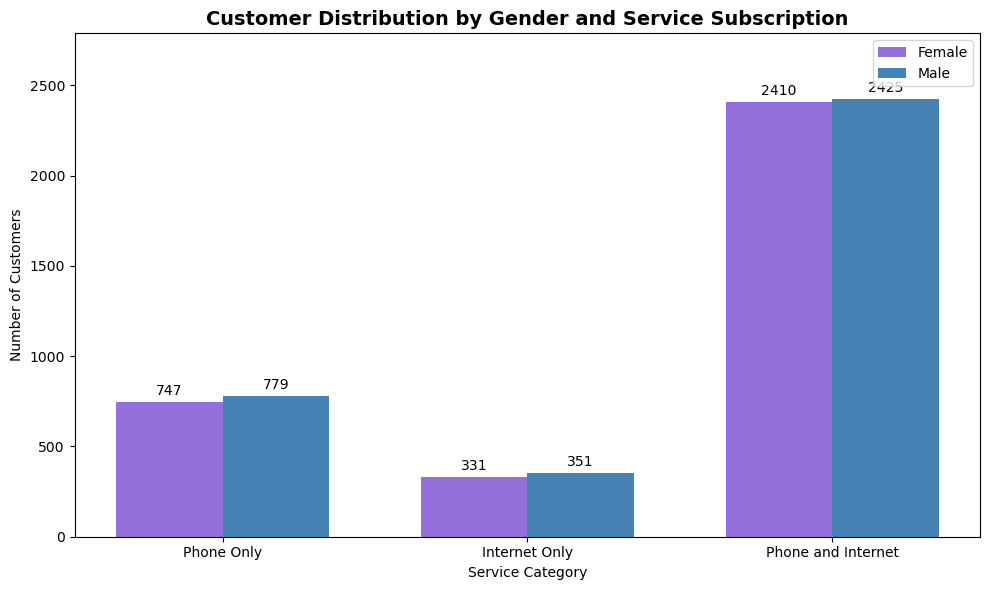

In [7]:

import matplotlib.pyplot as plt
import numpy as np

# Select the three service categories
service_categories = [
    "Phone Only",
    "Internet Only",
    "Phone and Internet"
]

female_counts = gender_service_summary.loc[
    "Female", service_categories
]

male_counts = gender_service_summary.loc[
    "Male", service_categories
]

# Bar positions
x = np.arange(len(service_categories))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

bars_female = ax.bar(
    x - width / 2,
    female_counts,
    width,
    label="Female",
    color="mediumpurple"
)

bars_male = ax.bar(
    x + width / 2,
    male_counts,
    width,
    label="Male",
    color="steelblue"
)

# Display customer counts above each bar
ax.bar_label(bars_female, padding=3)
ax.bar_label(bars_male, padding=3)

ax.set_title(
    "Customer Distribution by Gender and Service Subscription",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Service Category")
ax.set_ylabel("Number of Customers")

ax.set_xticks(x)
ax.set_xticklabels(service_categories)

ax.legend()
ax.set_ylim(0, max(male_counts.max(), female_counts.max()) * 1.15)

plt.tight_layout()
plt.show()


In [8]:
# calculate churn counts and churn rates

query = """
WITH customer_segments AS (
    SELECT
        gender,
        "Churn",
        CASE
            WHEN "PhoneService" = 'Yes'
                 AND "InternetService" = 'No'
                THEN 'Phone Only'

            WHEN "PhoneService" = 'No'
                 AND "InternetService" IN ('DSL', 'Fiber optic')
                THEN 'Internet Only'

            WHEN "PhoneService" = 'Yes'
                 AND "InternetService" IN ('DSL', 'Fiber optic')
                THEN 'Phone and Internet'

            ELSE 'Other'
        END AS service_category
    FROM public.telco_customers
)
SELECT
    gender,
    service_category,
    COUNT(*) AS total_customers,
    COUNT(*) FILTER (WHERE "Churn" = 'Yes') AS churned_customers,
    COUNT(*) FILTER (WHERE "Churn" = 'No') AS retained_customers,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE "Churn" = 'Yes')
        / NULLIF(COUNT(*), 0),
        2
    ) AS churn_rate_pct
FROM customer_segments
GROUP BY gender, service_category
ORDER BY gender, service_category;
"""

df_gender_churn = pd.read_sql_query(text(query), engine)

display(df_gender_churn)


,gender,service_category,total_customers,churned_customers,retained_customers,churn_rate_pct
0,Female,Internet Only,331,80,251,24.17
1,Female,Phone and Internet,2410,803,1607,33.32
2,Female,Phone Only,747,56,691,7.50
3,Male,Internet Only,351,90,261,25.64
4,Male,Phone and Internet,2425,783,1642,32.29
5,Male,Phone Only,779,57,722,7.32


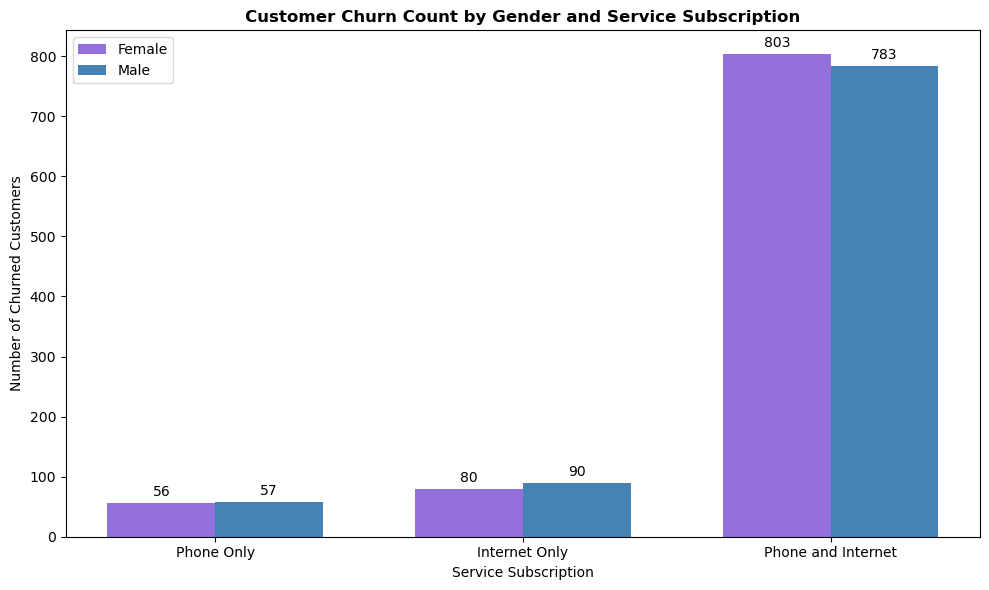

In [9]:

import matplotlib.pyplot as plt
import numpy as np

service_categories = [
    "Phone Only",
    "Internet Only",
    "Phone and Internet"
]

churn_pivot = df_gender_churn.pivot(
    index="service_category",
    columns="gender",
    values="churned_customers"
).reindex(service_categories)

x = np.arange(len(service_categories))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

female_bars = ax.bar(
    x - width / 2,
    churn_pivot["Female"],
    width,
    label="Female",
    color="mediumpurple"
)

male_bars = ax.bar(
    x + width / 2,
    churn_pivot["Male"],
    width,
    label="Male",
    color="steelblue"
)

ax.bar_label(female_bars, padding=3)
ax.bar_label(male_bars, padding=3)

ax.set_xticks(x)
ax.set_xticklabels(service_categories)
ax.set_ylabel("Number of Churned Customers")
ax.set_xlabel("Service Subscription")
ax.set_title(
    "Customer Churn Count by Gender and Service Subscription",
    fontweight="bold"
)
ax.legend()

plt.tight_layout()
plt.show()


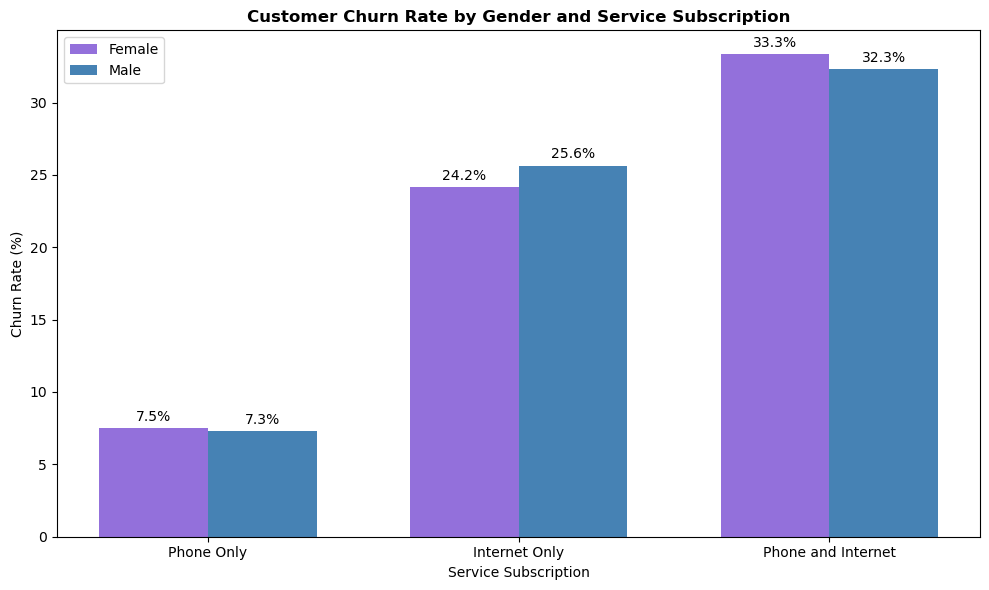

In [10]:

rate_pivot = df_gender_churn.pivot(
    index="service_category",
    columns="gender",
    values="churn_rate_pct"
).reindex(service_categories)

fig, ax = plt.subplots(figsize=(10, 6))

female_bars = ax.bar(
    x - width / 2,
    rate_pivot["Female"].astype(float),
    width,
    label="Female",
    color="mediumpurple"
)

male_bars = ax.bar(
    x + width / 2,
    rate_pivot["Male"].astype(float),
    width,
    label="Male",
    color="steelblue"
)

ax.bar_label(female_bars, fmt="%.1f%%", padding=3)
ax.bar_label(male_bars, fmt="%.1f%%", padding=3)

ax.set_xticks(x)
ax.set_xticklabels(service_categories)
ax.set_ylabel("Churn Rate (%)")
ax.set_xlabel("Service Subscription")
ax.set_title(
    "Customer Churn Rate by Gender and Service Subscription",
    fontweight="bold"
)
ax.legend()

plt.tight_layout()
plt.show()


In [11]:
# phone line - Single Line vs. Multiple Lines

query = """
SELECT
    CASE
        WHEN "MultipleLines" = 'No' THEN 'Single Line'
        WHEN "MultipleLines" = 'Yes' THEN 'Multiple Lines'
    END AS phone_line_category,

    COUNT(*) AS total_customers,

    COUNT(*) FILTER (
        WHERE "Churn" = 'Yes'
    ) AS churned_customers,

    COUNT(*) FILTER (
        WHERE "Churn" = 'No'
    ) AS retained_customers,

    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE "Churn" = 'Yes'
        ) / NULLIF(COUNT(*), 0),
        2
    ) AS churn_rate_pct

FROM public.telco_customers

WHERE "PhoneService" = 'Yes'
  AND "InternetService" = 'No'

GROUP BY phone_line_category
ORDER BY phone_line_category;
"""

df_phone_lines_churn = pd.read_sql_query(
    text(query),
    engine
)

display(df_phone_lines_churn)


,phone_line_category,total_customers,churned_customers,retained_customers,churn_rate_pct
0,Multiple Lines,342,10,332,2.92
1,Single Line,1184,103,1081,8.70


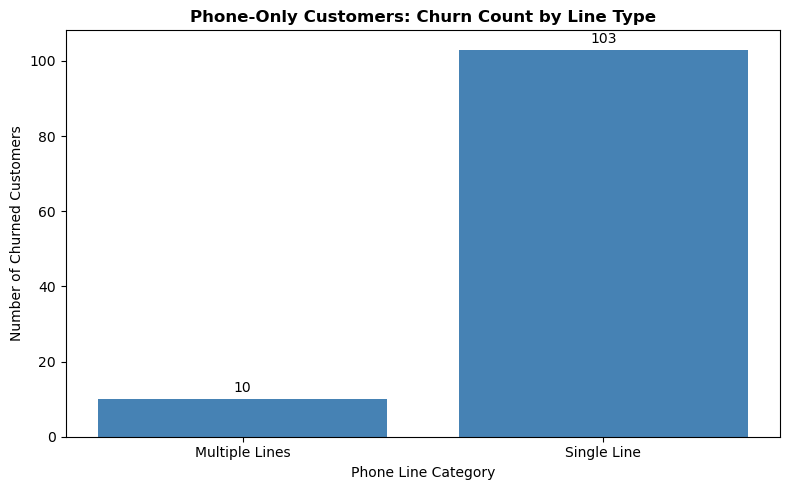

In [12]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    df_phone_lines_churn["phone_line_category"],
    df_phone_lines_churn["churned_customers"],
    color="steelblue"
)

ax.bar_label(bars, padding=3)

ax.set_title(
    "Phone-Only Customers: Churn Count by Line Type",
    fontweight="bold"
)
ax.set_xlabel("Phone Line Category")
ax.set_ylabel("Number of Churned Customers")

plt.tight_layout()
plt.show()


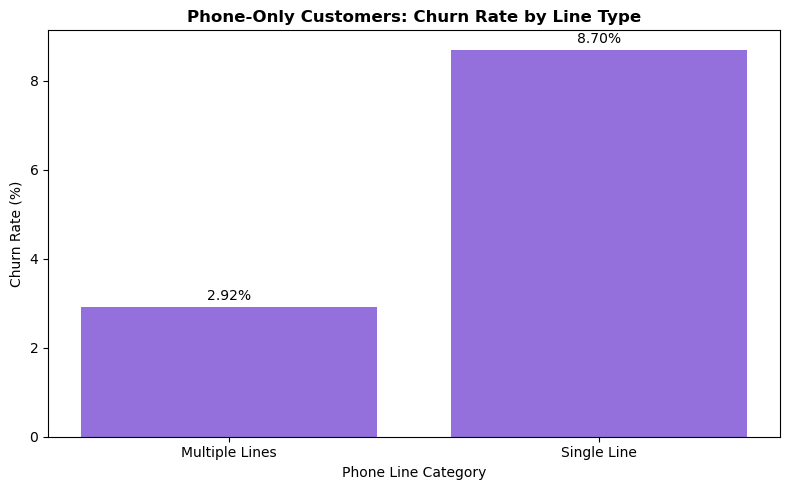

In [13]:

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    df_phone_lines_churn["phone_line_category"],
    df_phone_lines_churn["churn_rate_pct"].astype(float),
    color="mediumpurple"
)

ax.bar_label(bars, fmt="%.2f%%", padding=3)

ax.set_title(
    "Phone-Only Customers: Churn Rate by Line Type",
    fontweight="bold"
)
ax.set_xlabel("Phone Line Category")
ax.set_ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()


In [14]:

print(
    "Total phone-only customers:",
    df_phone_lines_churn["total_customers"].sum()
)

print(
    "Total churned:",
    df_phone_lines_churn["churned_customers"].sum()
)

print("Expected: 1526 customers, 113 churned")


Total phone-only customers: 1526
Total churned: 113
Expected: 1526 customers, 113 churned


In [15]:
# retrieving churned customers

query = """
SELECT
    "customerID",
    CASE
        WHEN "MultipleLines" = 'Yes' THEN 'Multiple Lines'
        WHEN "MultipleLines" = 'No' THEN 'Single Line'
    END AS phone_line_category,
    "Contract",
    tenure,
    "MonthlyCharges"
FROM public.telco_customers
WHERE "PhoneService" = 'Yes'
  AND "InternetService" = 'No'
  AND "Churn" = 'Yes'
ORDER BY phone_line_category, tenure;
"""

df_churned_phone = pd.read_sql_query(text(query), engine)

# Separate the two customer groups
df_multiple_lines = df_churned_phone[
    df_churned_phone["phone_line_category"] == "Multiple Lines"
]

df_single_line = df_churned_phone[
    df_churned_phone["phone_line_category"] == "Single Line"
]

print("Multiple-line churned customers:", len(df_multiple_lines))
display(df_multiple_lines)

print("Single-line churned customers:", len(df_single_line))
display(df_single_line)


Multiple-line churned customers: 10


,customerID,phone_line_category,Contract,tenure,MonthlyCharges
0,2565-JSLRY,Multiple Lines,Month-to-month,1,24.05
1,0568-ONFPC,Multiple Lines,Month-to-month,5,25.90
2,8785-EPNCG,Multiple Lines,Month-to-month,11,23.15
3,7083-YNSKY,Multiple Lines,Month-to-month,15,25.40
4,7812-FZHPE,Multiple Lines,Month-to-month,17,24.10
5,8515-OCTJS,Multiple Lines,Two year,25,24.75
6,0203-HHYIJ,Multiple Lines,One year,25,25.30
7,7951-QKZPL,Multiple Lines,Two year,33,24.50
8,4597-ELFTS,Multiple Lines,One year,56,24.90
9,1043-YCUTE,Multiple Lines,Two year,56,25.15


Single-line churned customers: 103


,customerID,phone_line_category,Contract,tenure,MonthlyCharges
10,4745-LSPLO,Single Line,Month-to-month,1,20.50
11,4800-VHZKI,Single Line,Month-to-month,1,19.90
12,7989-CHGTL,Single Line,Month-to-month,1,19.60
13,1029-QFBEN,Single Line,Month-to-month,1,19.55
14,3900-AQPHZ,Single Line,Month-to-month,1,19.90
...,...,...,...,...,...
108,3705-PSNGL,Single Line,One year,45,20.40
109,6532-YLWSI,Single Line,One year,53,20.80
110,0607-DAAHE,Single Line,Two year,53,19.75
111,6323-AYBRX,Single Line,Two year,59,19.35


In [16]:
# comparing tenure and monthly charges
comparison = (
    df_churned_phone
    .groupby("phone_line_category")
    .agg(
        churned_customers=("customerID", "count"),
        avg_tenure=("tenure", "mean"),
        median_tenure=("tenure", "median"),
        min_tenure=("tenure", "min"),
        max_tenure=("tenure", "max"),
        avg_monthly_charge=("MonthlyCharges", "mean"),
        median_monthly_charge=("MonthlyCharges", "median"),
        min_monthly_charge=("MonthlyCharges", "min"),
        max_monthly_charge=("MonthlyCharges", "max")
    )
    .round(2)
)

display(comparison.T)


phone_line_category,Multiple Lines,Single Line
churned_customers,10.00,103.00
avg_tenure,24.40,6.67
median_tenure,21.00,1.00
min_tenure,1.00,1.00
max_tenure,56.00,61.00
avg_monthly_charge,24.72,19.95
median_monthly_charge,24.82,19.90
min_monthly_charge,23.15,18.85
max_monthly_charge,25.90,21.05


In [17]:
# comparing contrct-types
contract_comparison = pd.crosstab(
    df_churned_phone["phone_line_category"],
    df_churned_phone["Contract"]
)

display(contract_comparison)

# Percentage distribution within each group
contract_pct = pd.crosstab(
    df_churned_phone["phone_line_category"],
    df_churned_phone["Contract"],
    normalize="index"
).mul(100).round(2)

display(contract_pct)


Contract,Month-to-month,One year,Two year
phone_line_category,,,
Multiple Lines,5,2,3
Single Line,94,7,2


Contract,Month-to-month,One year,Two year
phone_line_category,,,
Multiple Lines,50.00,20.0,30.00
Single Line,91.26,6.8,1.94


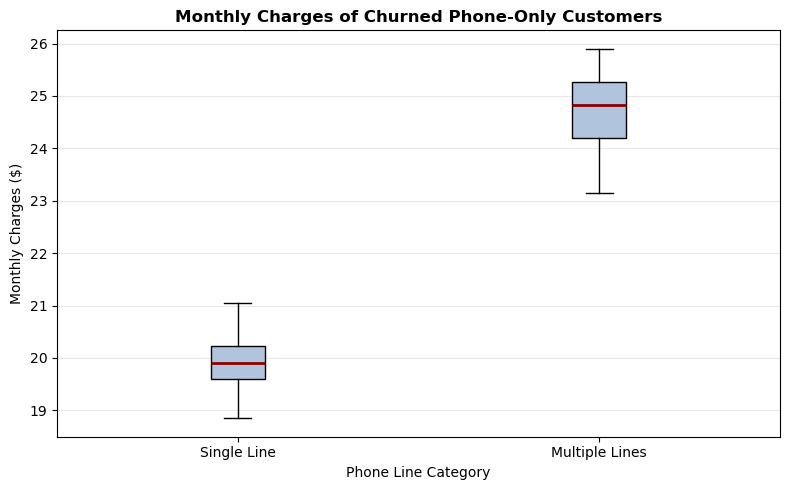

In [21]:
# visualizing monthly charges
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))

data = [
    df_single_line["MonthlyCharges"].dropna(),
    df_multiple_lines["MonthlyCharges"].dropna()
]

ax.boxplot(
    data,
    labels=["Single Line", "Multiple Lines"],
    patch_artist=True,
    boxprops={"facecolor": "lightsteelblue"},
    medianprops={"color": "darkred", "linewidth": 2}
)

ax.set_title(
    "Monthly Charges of Churned Phone-Only Customers",
    fontweight="bold"
)
ax.set_xlabel("Phone Line Category")
ax.set_ylabel("Monthly Charges ($)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


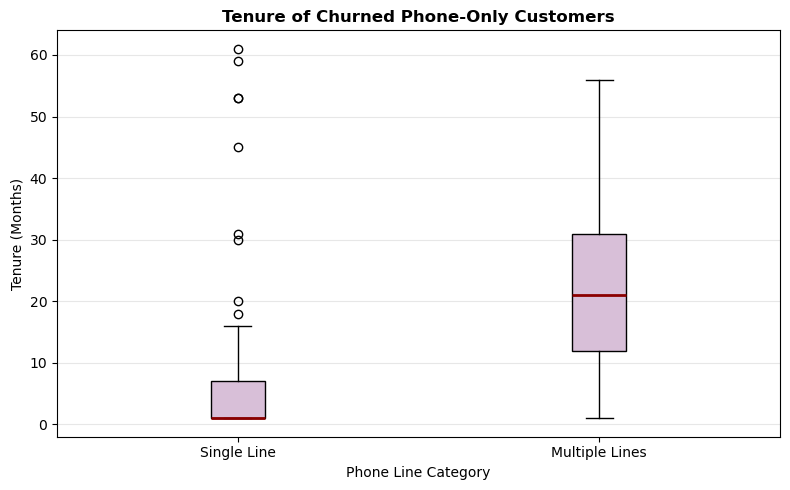

In [23]:
# visualizing tenure differences

fig, ax = plt.subplots(figsize=(8, 5))

ax.boxplot(
    [
        df_single_line["tenure"],
        df_multiple_lines["tenure"]
    ],
    labels=["Single Line", "Multiple Lines"],
    patch_artist=True,
    boxprops={"facecolor": "thistle"},
    medianprops={"color": "darkred", "linewidth": 2}
)

ax.set_title(
    "Tenure of Churned Phone-Only Customers",
    fontweight="bold"
)
ax.set_xlabel("Phone Line Category")
ax.set_ylabel("Tenure (Months)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [24]:
# retrieving all phone-only customers for comaprison

query = """
SELECT
    "customerID",
    CASE
        WHEN "MultipleLines" = 'Yes' THEN 'Multiple Lines'
        ELSE 'Single Line'
    END AS phone_line_category,
    "Churn",
    "Contract",
    tenure,
    "MonthlyCharges"
FROM public.telco_customers
WHERE "PhoneService" = 'Yes'
  AND "InternetService" = 'No';
"""

df_phone_all = pd.read_sql_query(text(query), engine)

display(
    pd.crosstab(
        df_phone_all["phone_line_category"],
        df_phone_all["Churn"]
    )
)


Churn,No,Yes
phone_line_category,,
Multiple Lines,332,10
Single Line,1081,103


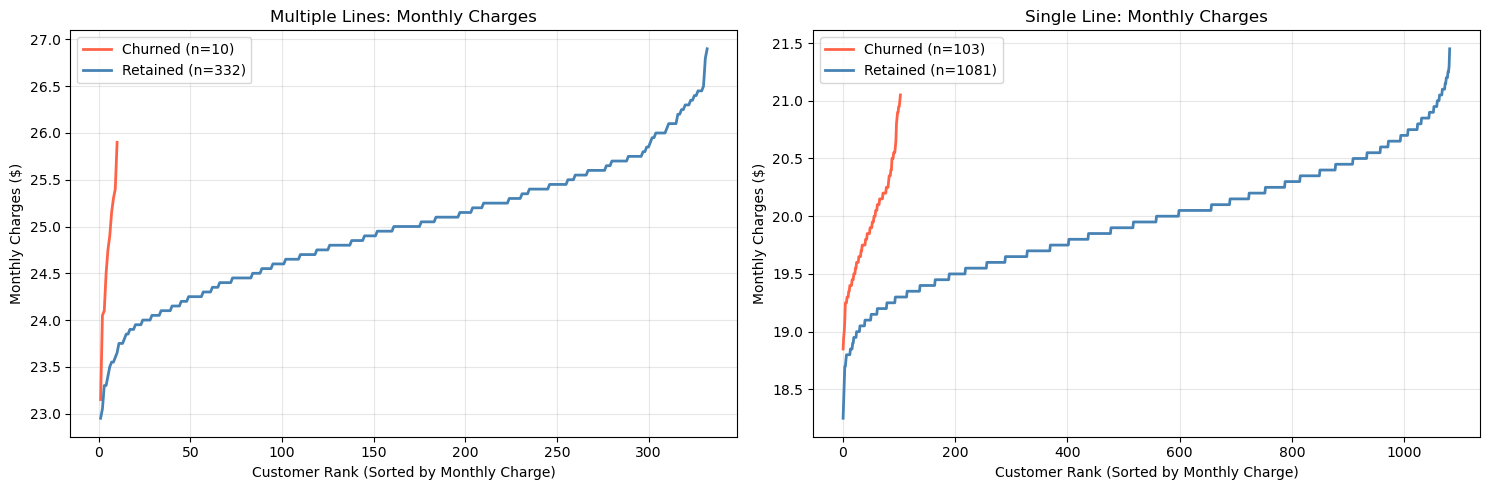

In [25]:
# Monthly charges: churned vs retained

import matplotlib.pyplot as plt

line_types = ["Multiple Lines", "Single Line"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, line_type in zip(axes, line_types):

    for churn_status, label, color in [
        ("Yes", "Churned", "tomato"),
        ("No", "Retained", "steelblue")
    ]:
        charges = (
            df_phone_all.loc[
                (df_phone_all["phone_line_category"] == line_type)
                & (df_phone_all["Churn"] == churn_status),
                "MonthlyCharges"
            ]
            .sort_values()
            .reset_index(drop=True)
        )

        ax.plot(
            range(1, len(charges) + 1),
            charges,
            label=f"{label} (n={len(charges)})",
            color=color,
            linewidth=2
        )

    ax.set_title(f"{line_type}: Monthly Charges")
    ax.set_xlabel("Customer Rank (Sorted by Monthly Charge)")
    ax.set_ylabel("Monthly Charges ($)")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


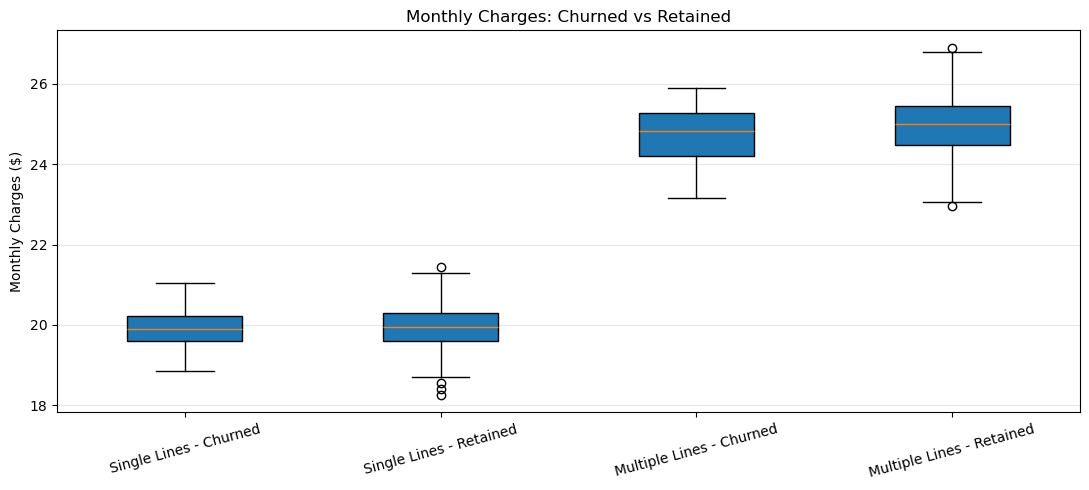

In [26]:
# monthly charge comparison - box plot

fig, ax = plt.subplots(figsize=(11, 5))

groups = [
    ("Single Lines - Churned", "Single Line", "Yes"),
    ("Single Lines - Retained", "Single Line", "No"),
    ("Multiple Lines - Churned", "Multiple Lines", "Yes"),
    ("Multiple Lines - Retained", "Multiple Lines", "No")
]

data = [
    df_phone_all.loc[
        (df_phone_all["phone_line_category"] == line_type)
        & (df_phone_all["Churn"] == churn_status),
        "MonthlyCharges"
    ].dropna()
    for _, line_type, churn_status in groups
]

ax.boxplot(
    data,
    labels=[group[0] for group in groups],
    patch_artist=True
)

ax.set_title("Monthly Charges: Churned vs Retained")
ax.set_ylabel("Monthly Charges ($)")
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [27]:
# tenure analysis - churned vs retained

tenure_summary = (
    df_phone_all
    .groupby(["phone_line_category", "Churn"])["tenure"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

display(tenure_summary)


count   mean  median  min  max
phone_line_category Churn                                
Multiple Lines      No       332  47.50    53.0    0   72
                    Yes       10  24.40    21.0    1   56
Single Line         No      1081  27.67    22.0    0   72
                    Yes      103   6.67     1.0    1   61

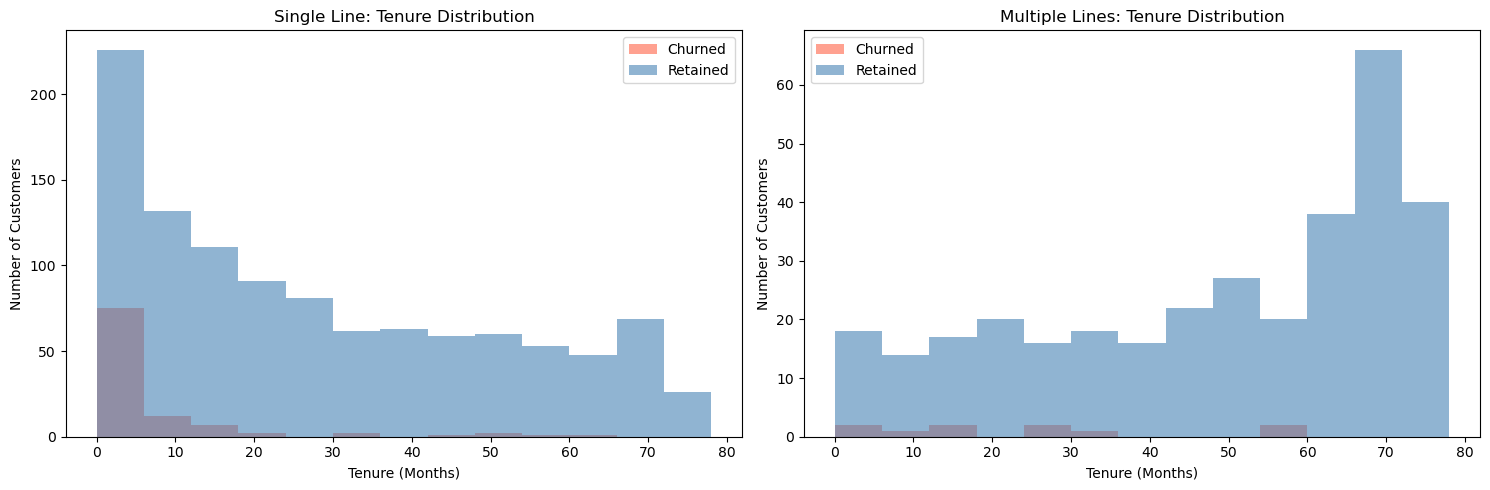

In [28]:
# visualize tenure distributions

import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

bins = np.arange(0, 79, 6)

for ax, line_type in zip(axes, ["Single Line", "Multiple Lines"]):

    for churn_status, label, color in [
        ("Yes", "Churned", "tomato"),
        ("No", "Retained", "steelblue")
    ]:
        tenure_values = df_phone_all.loc[
            (df_phone_all["phone_line_category"] == line_type)
            & (df_phone_all["Churn"] == churn_status),
            "tenure"
        ]

        ax.hist(
            tenure_values,
            bins=bins,
            alpha=0.6,
            label=label,
            color=color
        )

    ax.set_title(f"{line_type}: Tenure Distribution")
    ax.set_xlabel("Tenure (Months)")
    ax.set_ylabel("Number of Customers")
    ax.legend()

plt.tight_layout()
plt.show()


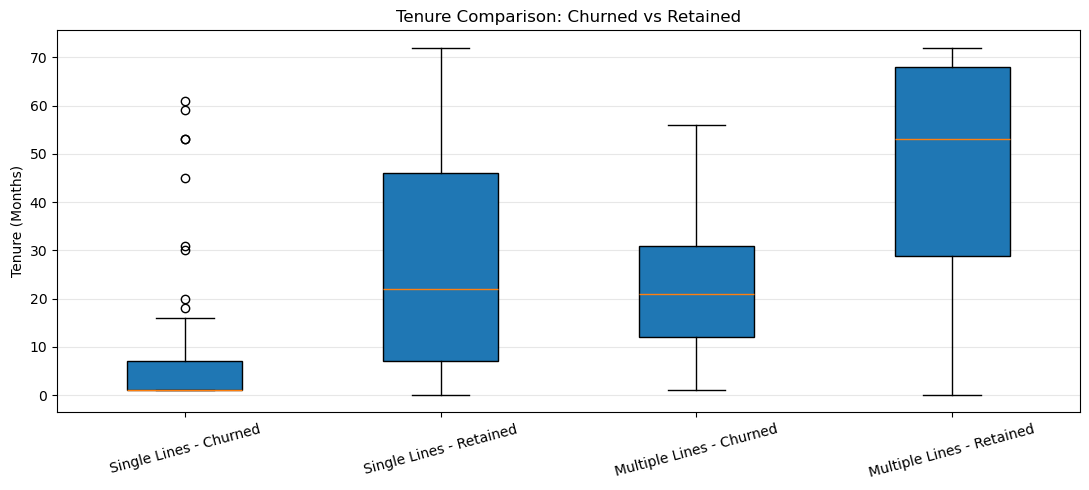

In [29]:

fig, ax = plt.subplots(figsize=(11, 5))

tenure_data = [
    df_phone_all.loc[
        (df_phone_all["phone_line_category"] == line_type)
        & (df_phone_all["Churn"] == churn_status),
        "tenure"
    ]
    for _, line_type, churn_status in groups
]

ax.boxplot(
    tenure_data,
    labels=[group[0] for group in groups],
    patch_artist=True
)

ax.set_title("Tenure Comparison: Churned vs Retained")
ax.set_ylabel("Tenure (Months)")
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [30]:
# investigating single -line tenure more closely

single_line = df_phone_all[
    df_phone_all["phone_line_category"] == "Single Line"
].copy()

single_line["tenure_group"] = pd.cut(
    single_line["tenure"],
    bins=[-1, 1, 6, 12, 24, 48, 72],
    labels=[
        "0-1 month",
        "2-6 months",
        "7-12 months",
        "13-24 months",
        "25-48 months",
        "49-72 months"
    ]
)

tenure_churn = pd.crosstab(
    single_line["tenure_group"],
    single_line["Churn"]
)

tenure_churn["Total"] = tenure_churn.sum(axis=1)

tenure_churn["Churn Rate (%)"] = (
    tenure_churn["Yes"] / tenure_churn["Total"] * 100
).round(2)

display(tenure_churn)


Churn,No,Yes,Total,Churn Rate (%)
tenure_group,,,,
0-1 month,107,57,164,34.76
2-6 months,145,19,164,11.59
7-12 months,131,13,144,9.03
13-24 months,193,7,200,3.50
25-48 months,259,3,262,1.15
49-72 months,246,4,250,1.60


In [31]:
# contract distribution across the dataset

query = """
SELECT
    "Contract",
    COUNT(*) AS total_customers,
    COUNT(*) FILTER (
        WHERE "Churn" = 'Yes'
    ) AS churned_customers,
    COUNT(*) FILTER (
        WHERE "Churn" = 'No'
    ) AS retained_customers,
    ROUND(
        100.0 * COUNT(*) / SUM(COUNT(*)) OVER (),
        2
    ) AS customer_share_pct,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE "Churn" = 'Yes')
        / NULLIF(COUNT(*), 0),
        2
    ) AS churn_rate_pct
FROM public.telco_customers
GROUP BY "Contract"
ORDER BY churn_rate_pct DESC;
"""

df_contract_overall = pd.read_sql_query(text(query), engine)

display(df_contract_overall)


,Contract,total_customers,churned_customers,retained_customers,customer_share_pct,churn_rate_pct
0,Month-to-month,3875,1655,2220,55.02,42.71
1,One year,1473,166,1307,20.91,11.27
2,Two year,1695,48,1647,24.07,2.83


In [32]:

contract_phone_summary = (
    df_phone_all
    .groupby(["phone_line_category", "Contract"])
    .agg(
        total_customers=("customerID", "count"),
        churned_customers=("Churn", lambda x: (x == "Yes").sum()),
        retained_customers=("Churn", lambda x: (x == "No").sum())
    )
    .reset_index()
)

contract_phone_summary["churn_rate_pct"] = (
    contract_phone_summary["churned_customers"]
    / contract_phone_summary["total_customers"]
    * 100
).round(2)

display(contract_phone_summary)


,phone_line_category,Contract,total_customers,churned_customers,retained_customers,churn_rate_pct
0,Multiple Lines,Month-to-month,46,5,41,10.87
1,Multiple Lines,One year,64,2,62,3.12
2,Multiple Lines,Two year,232,3,229,1.29
3,Single Line,Month-to-month,478,94,384,19.67
4,Single Line,One year,300,7,293,2.33
5,Single Line,Two year,406,2,404,0.49


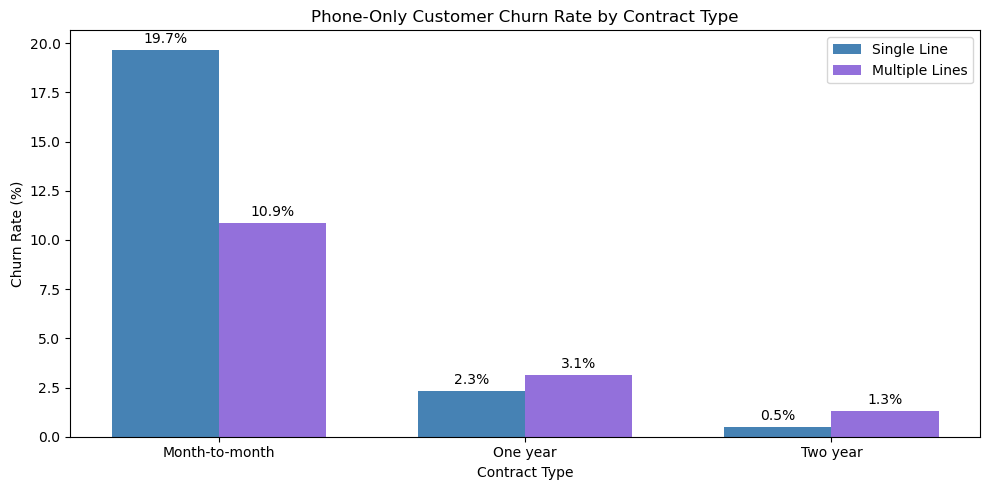

In [33]:
# visualizing churn rates by contract

import numpy as np

contract_order = ["Month-to-month", "One year", "Two year"]

contract_pivot = contract_phone_summary.pivot(
    index="Contract",
    columns="phone_line_category",
    values="churn_rate_pct"
).reindex(contract_order)

x = np.arange(len(contract_order))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

bars_single = ax.bar(
    x - width / 2,
    contract_pivot["Single Line"],
    width,
    label="Single Line",
    color="steelblue"
)

bars_multiple = ax.bar(
    x + width / 2,
    contract_pivot["Multiple Lines"],
    width,
    label="Multiple Lines",
    color="mediumpurple"
)

ax.bar_label(bars_single, fmt="%.1f%%", padding=3)
ax.bar_label(bars_multiple, fmt="%.1f%%", padding=3)

ax.set_xticks(x)
ax.set_xticklabels(contract_order)
ax.set_xlabel("Contract Type")
ax.set_ylabel("Churn Rate (%)")
ax.set_title("Phone-Only Customer Churn Rate by Contract Type")
ax.legend()

plt.tight_layout()
plt.show()


In [34]:
# retrieving phone only customers - sebior citizens and normal citizens
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sqlalchemy import text

query = """
SELECT
    "customerID",
    CASE
        WHEN "SeniorCitizen" = 1 THEN 'Senior Citizen'
        ELSE 'Non-Senior Citizen'
    END AS age_category,
    "Churn",
    tenure,
    "MonthlyCharges"
FROM public.telco_customers
WHERE "PhoneService" = 'Yes'
  AND "InternetService" = 'No'
"""

df_senior_phone = pd.read_sql_query(text(query), engine)

display(df_senior_phone.head())
print("Total phone-only customers:", len(df_senior_phone))

,customerID,age_category,Churn,tenure,MonthlyCharges
0,7469-LKBCI,Non-Senior Citizen,No,16,18.95
1,8191-XWSZG,Non-Senior Citizen,No,52,20.65
2,1680-VDCWW,Non-Senior Citizen,No,12,19.80
3,1066-JKSGK,Non-Senior Citizen,Yes,1,20.15
4,7310-EGVHZ,Non-Senior Citizen,No,1,20.20


Total phone-only customers: 1526


In [35]:
# churned vs retained customers by age category
senior_churn_summary = (
    df_senior_phone
    .groupby(["age_category", "Churn"])
    .size()
    .unstack(fill_value=0)
)

senior_churn_summary = senior_churn_summary.reindex(
    columns=["No", "Yes"],
    fill_value=0
)

senior_churn_summary = senior_churn_summary.rename(
    columns={
        "No": "Retained",
        "Yes": "Churned"
    }
)

senior_churn_summary["Total"] = (
    senior_churn_summary["Retained"]
    + senior_churn_summary["Churned"]
)

senior_churn_summary["Churn Rate (%)"] = (
    senior_churn_summary["Churned"]
    / senior_churn_summary["Total"] * 100
).round(2)

senior_churn_summary["Retention Rate (%)"] = (
    senior_churn_summary["Retained"]
    / senior_churn_summary["Total"] * 100
).round(2)

display(senior_churn_summary)

Churn,Retained,Churned,Total,Churn Rate (%),Retention Rate (%)
age_category,,,,,
Non-Senior Citizen,1366,108,1474,7.33,92.67
Senior Citizen,47,5,52,9.62,90.38


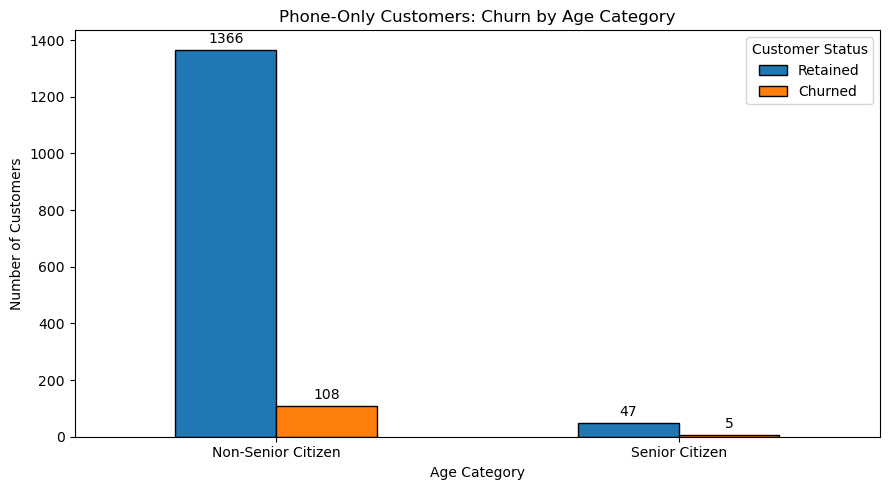

In [36]:
ax = senior_churn_summary[
    ["Retained", "Churned"]
].plot(
    kind="bar",
    figsize=(9, 5),
    rot=0,
    edgecolor="black"
)

plt.title("Phone-Only Customers: Churn by Age Category")
plt.xlabel("Age Category")
plt.ylabel("Number of Customers")
plt.legend(title="Customer Status")

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.tight_layout()
plt.show()

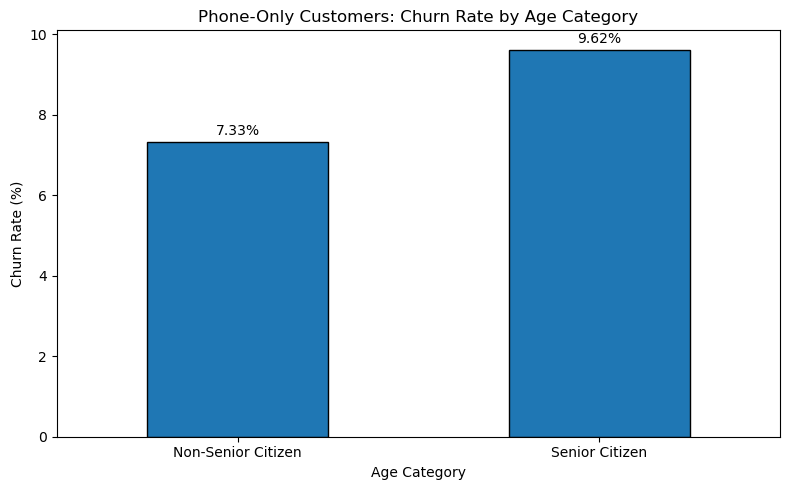

In [37]:
# visualizing churn rates
ax = senior_churn_summary["Churn Rate (%)"].plot(
    kind="bar",
    figsize=(8, 5),
    rot=0,
    edgecolor="black"
)

plt.title("Phone-Only Customers: Churn Rate by Age Category")
plt.xlabel("Age Category")
plt.ylabel("Churn Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()

In [38]:
# Tenure analysis - churned vs retained
senior_tenure_summary = (
    df_senior_phone
    .groupby(["age_category", "Churn"])["tenure"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Min="min",
        Max="max",
        Std_Dev="std"
    )
    .round(2)
)

display(senior_tenure_summary)

Count   Mean  Median  Min  Max  Std_Dev
age_category       Churn                                         
Non-Senior Citizen No      1366  31.90    27.0    0   72    24.02
                   Yes      108   8.42     1.0    1   61    14.17
Senior Citizen     No        47  45.00    51.0    2   72    24.31
                   Yes        5   4.40     1.0    1   11     4.77

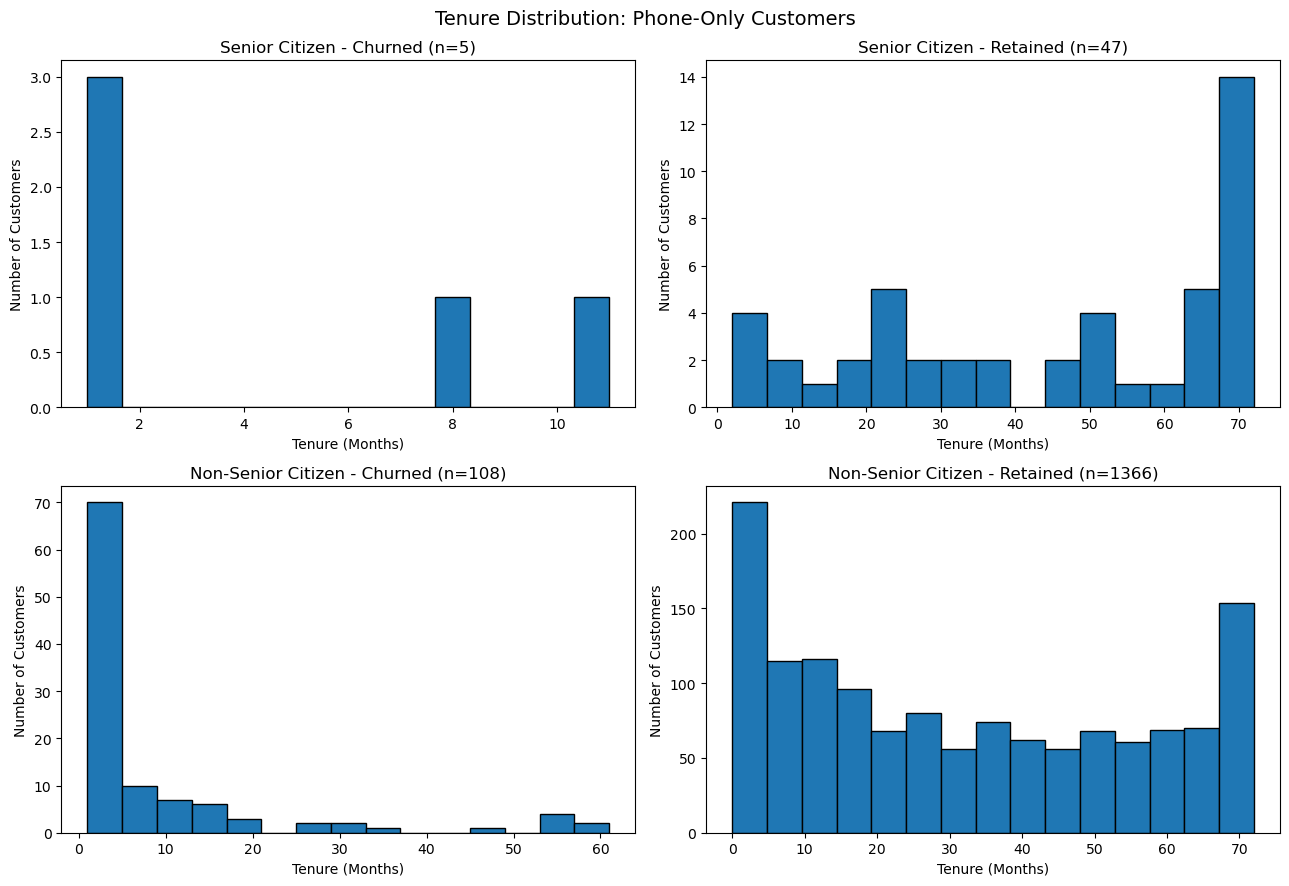

In [39]:
# tenure distributions using histograms
age_categories = [
    "Senior Citizen",
    "Non-Senior Citizen"
]

churn_statuses = ["Yes", "No"]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for i, age in enumerate(age_categories):
    for j, churn in enumerate(churn_statuses):

        subset = df_senior_phone[
            (df_senior_phone["age_category"] == age)
            & (df_senior_phone["Churn"] == churn)
        ]

        axes[i, j].hist(
            subset["tenure"],
            bins=15,
            edgecolor="black"
        )

        status = "Churned" if churn == "Yes" else "Retained"

        axes[i, j].set_title(
            f"{age} - {status} (n={len(subset)})"
        )
        axes[i, j].set_xlabel("Tenure (Months)")
        axes[i, j].set_ylabel("Number of Customers")

plt.suptitle(
    "Tenure Distribution: Phone-Only Customers",
    fontsize=14
)
plt.tight_layout()
plt.show()

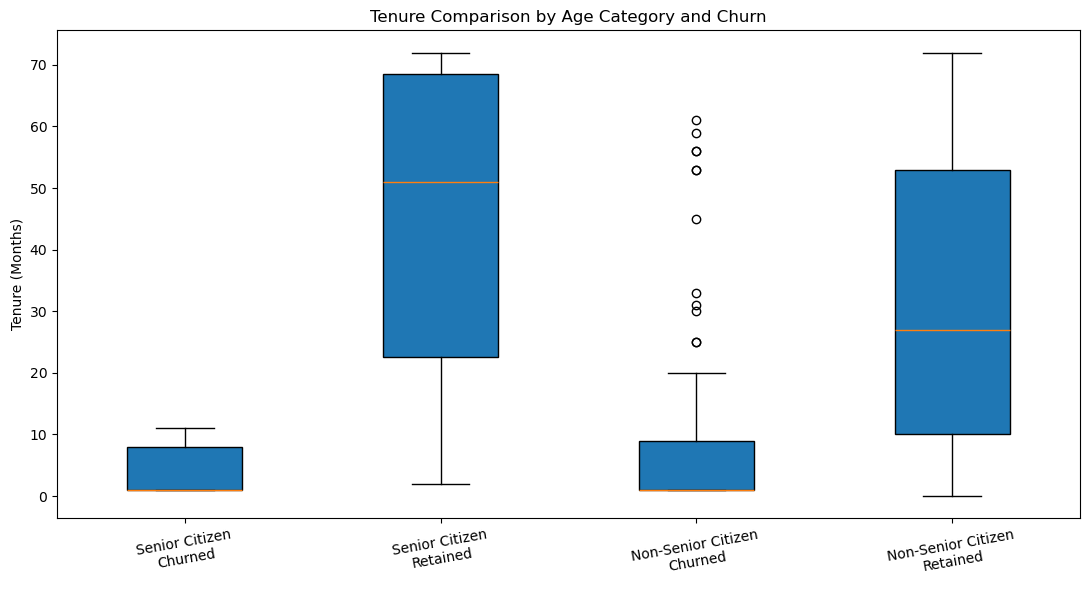

In [40]:
# tenure box plot
groups = []
labels = []

for age in age_categories:
    for churn in churn_statuses:

        values = df_senior_phone.loc[
            (df_senior_phone["age_category"] == age)
            & (df_senior_phone["Churn"] == churn),
            "tenure"
        ].dropna()

        groups.append(values)

        status = "Churned" if churn == "Yes" else "Retained"
        labels.append(f"{age}\n{status}")

plt.figure(figsize=(11, 6))

plt.boxplot(
    groups,
    labels=labels,
    patch_artist=True
)

plt.title("Tenure Comparison by Age Category and Churn")
plt.ylabel("Tenure (Months)")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

In [41]:
# Monthlycharges Analysis - churned vs retained
senior_charges_summary = (
    df_senior_phone
    .groupby(["age_category", "Churn"])["MonthlyCharges"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Min="min",
        Max="max",
        Std_Dev="std"
    )
    .round(2)
)

display(senior_charges_summary)

Count   Mean  Median    Min    Max  Std_Dev
age_category       Churn                                             
Non-Senior Citizen No      1366  21.10   20.15  18.25  26.90     2.18
                   Yes      108  20.39   20.00  18.85  25.90     1.48
Senior Citizen     No        47  22.11   20.50  18.95  25.70     2.60
                   Yes        5  19.99   19.95  19.45  20.85     0.54

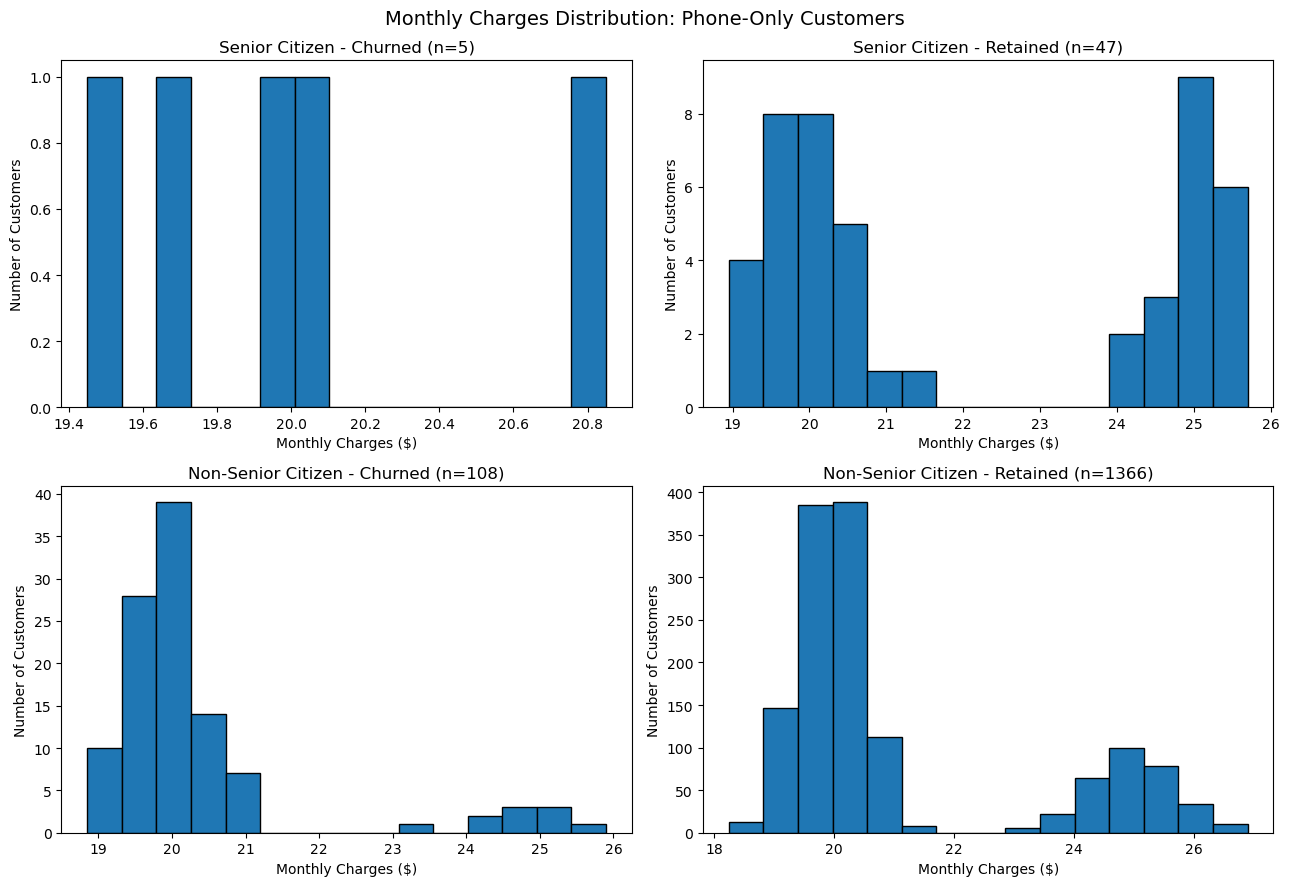

In [42]:
# monthly charges distribution
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for i, age in enumerate(age_categories):
    for j, churn in enumerate(churn_statuses):

        subset = df_senior_phone[
            (df_senior_phone["age_category"] == age)
            & (df_senior_phone["Churn"] == churn)
        ]

        axes[i, j].hist(
            subset["MonthlyCharges"],
            bins=15,
            edgecolor="black"
        )

        status = "Churned" if churn == "Yes" else "Retained"

        axes[i, j].set_title(
            f"{age} - {status} (n={len(subset)})"
        )
        axes[i, j].set_xlabel("Monthly Charges ($)")
        axes[i, j].set_ylabel("Number of Customers")

plt.suptitle(
    "Monthly Charges Distribution: Phone-Only Customers",
    fontsize=14
)
plt.tight_layout()
plt.show()

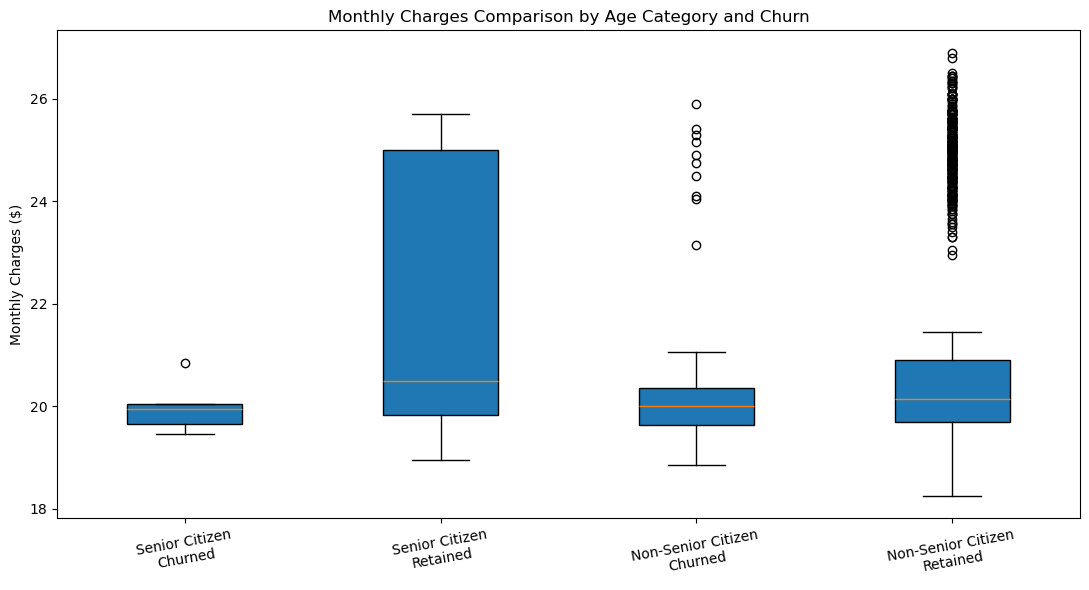

In [43]:
#monthly charges boxplot
groups = []
labels = []

for age in age_categories:
    for churn in churn_statuses:

        values = df_senior_phone.loc[
            (df_senior_phone["age_category"] == age)
            & (df_senior_phone["Churn"] == churn),
            "MonthlyCharges"
        ].dropna()

        groups.append(values)

        status = "Churned" if churn == "Yes" else "Retained"
        labels.append(f"{age}\n{status}")

plt.figure(figsize=(11, 6))

plt.boxplot(
    groups,
    labels=labels,
    patch_artist=True
)

plt.title("Monthly Charges Comparison by Age Category and Churn")
plt.ylabel("Monthly Charges ($)")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

In [45]:
# comparing senior citizens and non-senior citizens across single-line and multiple-line phone subscriptions.
# retrieving data from postgreSQL
query = """
SELECT
    "customerID",
    CASE
        WHEN "SeniorCitizen" = 1 THEN 'Senior Citizen'
        ELSE 'Non-Senior Citizen'
    END AS age_category,

    CASE
        WHEN "MultipleLines" = 'Yes' THEN 'Multiple Lines'
        ELSE 'Single Line'
    END AS phone_line_category,

    "Churn"

FROM public.telco_customers

WHERE "PhoneService" = 'Yes'
  AND "InternetService" = 'No'
"""

df_senior_phone_lines = pd.read_sql_query(text(query), engine)

display(df_senior_phone_lines.head())

print("Total phone-only customers:", len(df_senior_phone_lines))

,customerID,age_category,phone_line_category,Churn
0,7469-LKBCI,Non-Senior Citizen,Single Line,No
1,8191-XWSZG,Non-Senior Citizen,Single Line,No
2,1680-VDCWW,Non-Senior Citizen,Single Line,No
3,1066-JKSGK,Non-Senior Citizen,Single Line,Yes
4,7310-EGVHZ,Non-Senior Citizen,Single Line,No


Total phone-only customers: 1526


In [46]:
# churned vs retained customer counts
senior_lines_summary = (
    df_senior_phone_lines
    .groupby(["age_category", "phone_line_category", "Churn"])
    .size()
    .unstack(fill_value=0)
)

senior_lines_summary = senior_lines_summary.reindex(
    columns=["No", "Yes"],
    fill_value=0
)

senior_lines_summary = senior_lines_summary.rename(
    columns={
        "No": "Retained",
        "Yes": "Churned"
    }
)

senior_lines_summary["Total"] = (
    senior_lines_summary["Retained"]
    + senior_lines_summary["Churned"]
)

senior_lines_summary["Churn Rate (%)"] = (
    senior_lines_summary["Churned"]
    / senior_lines_summary["Total"] * 100
).round(2)

display(senior_lines_summary)

Churn                                   Retained  Churned  Total  \
age_category       phone_line_category                             
Non-Senior Citizen Multiple Lines            312       10    322   
                   Single Line              1054       98   1152   
Senior Citizen     Multiple Lines             20        0     20   
                   Single Line                27        5     32   

Churn                                   Churn Rate (%)  
age_category       phone_line_category                  
Non-Senior Citizen Multiple Lines                 3.11  
                   Single Line                    8.51  
Senior Citizen     Multiple Lines                 0.00  
                   Single Line                   15.62

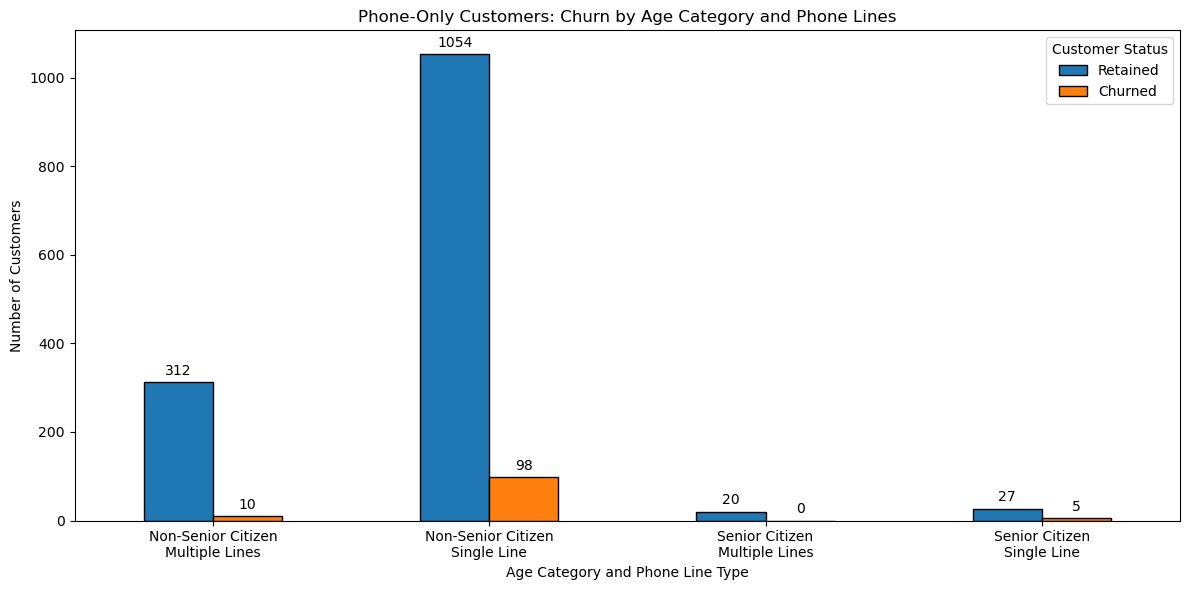

In [47]:
# visualizing churned and retained customer counts
ax = senior_lines_summary[
    ["Retained", "Churned"]
].plot(
    kind="bar",
    figsize=(12, 6),
    rot=0,
    edgecolor="black"
)

plt.title(
    "Phone-Only Customers: Churn by Age Category and Phone Lines"
)
plt.xlabel("Age Category and Phone Line Type")
plt.ylabel("Number of Customers")

ax.set_xticklabels([
    f"{age}\n{line}"
    for age, line in senior_lines_summary.index
])

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.legend(title="Customer Status")
plt.tight_layout()
plt.show()

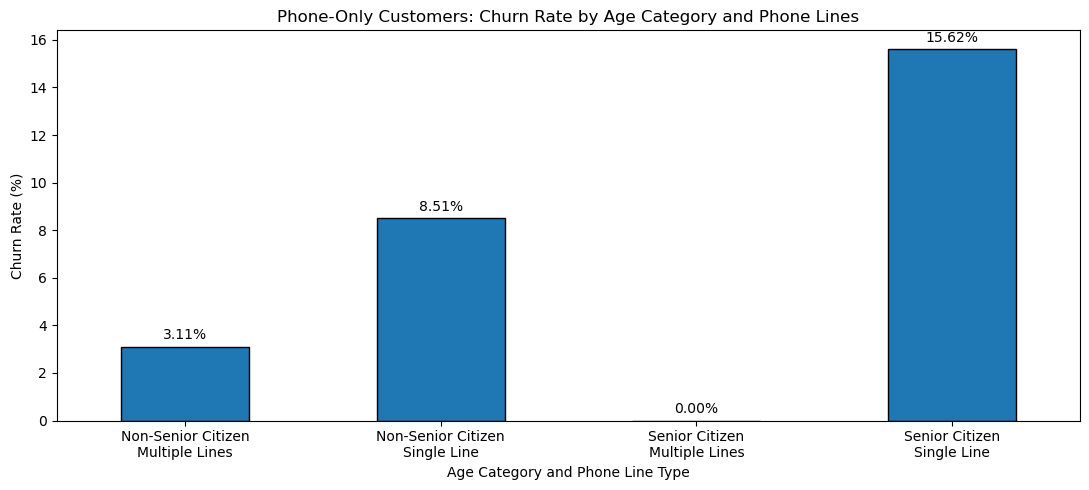

In [48]:
# comparing churn rates across the four groups
ax = senior_lines_summary["Churn Rate (%)"].plot(
    kind="bar",
    figsize=(11, 5),
    rot=0,
    edgecolor="black"
)

plt.title(
    "Phone-Only Customers: Churn Rate by Age Category and Phone Lines"
)
plt.xlabel("Age Category and Phone Line Type")
plt.ylabel("Churn Rate (%)")

ax.set_xticklabels([
    f"{age}\n{line}"
    for age, line in senior_lines_summary.index
])

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()

In [49]:
# Phone-Only Services EDA to two additional customer characteristics:
# 1. Partner: Customers with a partner vs. customers without a partner.
# 2. Dependents: Customers with dependents vs. customers without dependents.

import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import text

query = """
SELECT
    "customerID",
    "Partner",
    "Dependents",
    "MultipleLines",
    "Churn",
    tenure,
    "MonthlyCharges"
FROM public.telco_customers
WHERE "PhoneService" = 'Yes'
  AND "InternetService" = 'No'
"""

df_family_phone = pd.read_sql_query(text(query), engine)

df_family_phone["phone_line_category"] = (
    df_family_phone["MultipleLines"]
    .map({"Yes": "Multiple Lines", "No": "Single Line"})
)

print("Total phone-only customers:", len(df_family_phone))
display(df_family_phone.head())

Total phone-only customers: 1526


,customerID,Partner,Dependents,MultipleLines,Churn,tenure,MonthlyCharges,phone_line_category
0,7469-LKBCI,No,No,No,No,16,18.95,Single Line
1,8191-XWSZG,No,No,No,No,52,20.65,Single Line
2,1680-VDCWW,Yes,No,No,No,12,19.80,Single Line
3,1066-JKSGK,No,No,No,Yes,1,20.15,Single Line
4,7310-EGVHZ,No,No,No,No,1,20.20,Single Line


In [50]:
# creating a resuable analysis function
def analyze_phone_segment(df, column, label):

    data = df.copy()

    data["customer_category"] = data[column].map({
        "Yes": f"With {label}",
        "No": f"Without {label}"
    })

    # 1. Churn summary
    churn_summary = (
        data.groupby(["customer_category", "Churn"])
        .size()
        .unstack(fill_value=0)
        .reindex(columns=["No", "Yes"], fill_value=0)
        .rename(columns={"No": "Retained", "Yes": "Churned"})
    )

    churn_summary["Total"] = (
        churn_summary["Retained"] + churn_summary["Churned"]
    )

    churn_summary["Churn Rate (%)"] = (
        churn_summary["Churned"] / churn_summary["Total"] * 100
    ).round(2)

    print(f"\n{label.upper()} — CHURN SUMMARY")
    display(churn_summary)

    # 2. Churned and retained counts
    ax = churn_summary[["Retained", "Churned"]].plot(
        kind="bar", figsize=(9, 5), rot=0, edgecolor="black"
    )

    plt.title(f"Phone-Only: Churn by {label}")
    plt.xlabel(label)
    plt.ylabel("Number of Customers")

    for container in ax.containers:
        ax.bar_label(container, padding=3)

    plt.tight_layout()
    plt.show()

    # 3. Churn rate
    ax = churn_summary["Churn Rate (%)"].plot(
        kind="bar", figsize=(8, 5), rot=0, edgecolor="black"
    )

    plt.title(f"Phone-Only: Churn Rate by {label}")
    plt.xlabel(label)
    plt.ylabel("Churn Rate (%)")

    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f%%", padding=3)

    plt.tight_layout()
    plt.show()

    # 4. Tenure summary
    tenure_summary = (
        data.groupby(["customer_category", "Churn"])["tenure"]
        .agg(
            Count="count",
            Mean="mean",
            Median="median",
            Min="min",
            Max="max",
            Std_Dev="std"
        )
        .round(2)
    )

    print(f"\n{label.upper()} — TENURE SUMMARY")
    display(tenure_summary)

    # 5. Monthly charges summary
    charges_summary = (
        data.groupby(["customer_category", "Churn"])["MonthlyCharges"]
        .agg(
            Count="count",
            Mean="mean",
            Median="median",
            Min="min",
            Max="max",
            Std_Dev="std"
        )
        .round(2)
    )

    print(f"\n{label.upper()} — MONTHLY CHARGES SUMMARY")
    display(charges_summary)

    # 6. Histograms and box plots
    categories = [
        f"With {label}",
        f"Without {label}"
    ]
    statuses = ["Yes", "No"]

    for variable, unit in [
        ("tenure", "Months"),
        ("MonthlyCharges", "$")
    ]:

        fig, axes = plt.subplots(2, 2, figsize=(13, 8))

        groups = []
        group_labels = []

        for i, category in enumerate(categories):
            for j, churn in enumerate(statuses):

                subset = data.loc[
                    (data["customer_category"] == category)
                    & (data["Churn"] == churn),
                    variable
                ].dropna()

                status_label = (
                    "Churned" if churn == "Yes" else "Retained"
                )

                axes[i, j].hist(
                    subset,
                    bins=15,
                    edgecolor="black"
                )

                axes[i, j].set_title(
                    f"{category} - {status_label} (n={len(subset)})"
                )
                axes[i, j].set_xlabel(f"{variable} ({unit})")
                axes[i, j].set_ylabel("Customers")

                groups.append(subset)
                group_labels.append(
                    f"{category}\n{status_label}"
                )

        plt.suptitle(
            f"Phone-Only: {variable} Distribution by {label}"
        )
        plt.tight_layout()
        plt.show()

        plt.figure(figsize=(11, 6))

        plt.boxplot(
            groups,
            labels=group_labels,
            patch_artist=True
        )

        plt.title(
            f"Phone-Only: {variable} by {label} and Churn"
        )
        plt.ylabel(f"{variable} ({unit})")
        plt.tight_layout()
        plt.show()

    # 7. Single-line vs multiple-line churn
    line_summary = (
        data.groupby(
            ["customer_category", "phone_line_category", "Churn"]
        )
        .size()
        .unstack(fill_value=0)
        .reindex(columns=["No", "Yes"], fill_value=0)
        .rename(columns={"No": "Retained", "Yes": "Churned"})
    )

    line_summary["Total"] = (
        line_summary["Retained"] + line_summary["Churned"]
    )

    line_summary["Churn Rate (%)"] = (
        line_summary["Churned"] / line_summary["Total"] * 100
    ).round(2)

    print(f"\n{label.upper()} — PHONE LINE CHURN SUMMARY")
    display(line_summary)

    # Customer counts by line type
    ax = line_summary[["Retained", "Churned"]].plot(
        kind="bar", figsize=(12, 6), rot=0, edgecolor="black"
    )

    ax.set_xticklabels([
        f"{category}\n{line}"
        for category, line in line_summary.index
    ])

    plt.title(f"Phone-Only: {label} and Phone-Line Churn")
    plt.xlabel("Customer Category / Phone-Line Type")
    plt.ylabel("Number of Customers")

    for container in ax.containers:
        ax.bar_label(container, padding=3)

    plt.tight_layout()
    plt.show()

    # Churn rates by line type
    ax = line_summary["Churn Rate (%)"].plot(
        kind="bar", figsize=(11, 5), rot=0, edgecolor="black"
    )

    ax.set_xticklabels([
        f"{category}\n{line}"
        for category, line in line_summary.index
    ])

    plt.title(f"Phone-Only: Churn Rates by {label} and Phone Lines")
    plt.xlabel("Customer Category / Phone-Line Type")
    plt.ylabel("Churn Rate (%)")

    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f%%", padding=3)

    plt.tight_layout()
    plt.show()

    return churn_summary, tenure_summary, charges_summary, line_summary


PARTNER — CHURN SUMMARY


Churn,Retained,Churned,Total,Churn Rate (%)
customer_category,,,,
With Partner,709,29,738,3.93
Without Partner,704,84,788,10.66


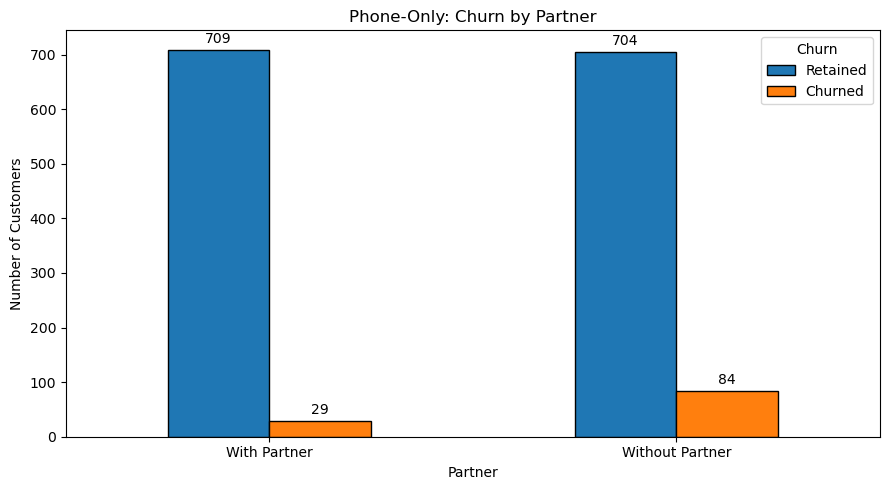

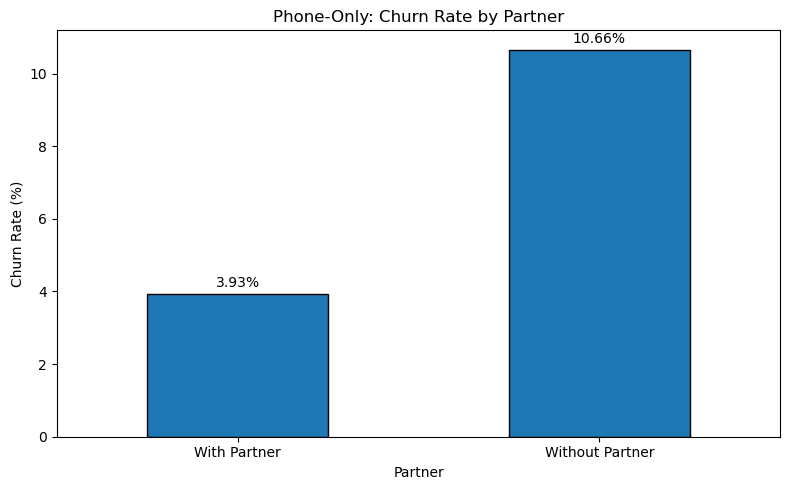


PARTNER — TENURE SUMMARY


Count   Mean  Median  Min  Max  Std_Dev
customer_category Churn                                         
With Partner      No       709  40.47    42.0    0   72    23.47
                  Yes       29  13.52     6.0    1   61    17.54
Without Partner   No       704  24.13    17.0    0   72    21.93
                  Yes       84   6.42     1.0    1   59    12.01


PARTNER — MONTHLY CHARGES SUMMARY


Count   Mean  Median    Min   Max  Std_Dev
customer_category Churn                                            
With Partner      No       709  21.49   20.25  18.40  26.9     2.38
                  Yes       29  20.65   19.95  19.00  25.9     1.82
Without Partner   No       704  20.78   20.05  18.25  26.5     1.94
                  Yes       84  20.27   20.02  18.85  25.4     1.31

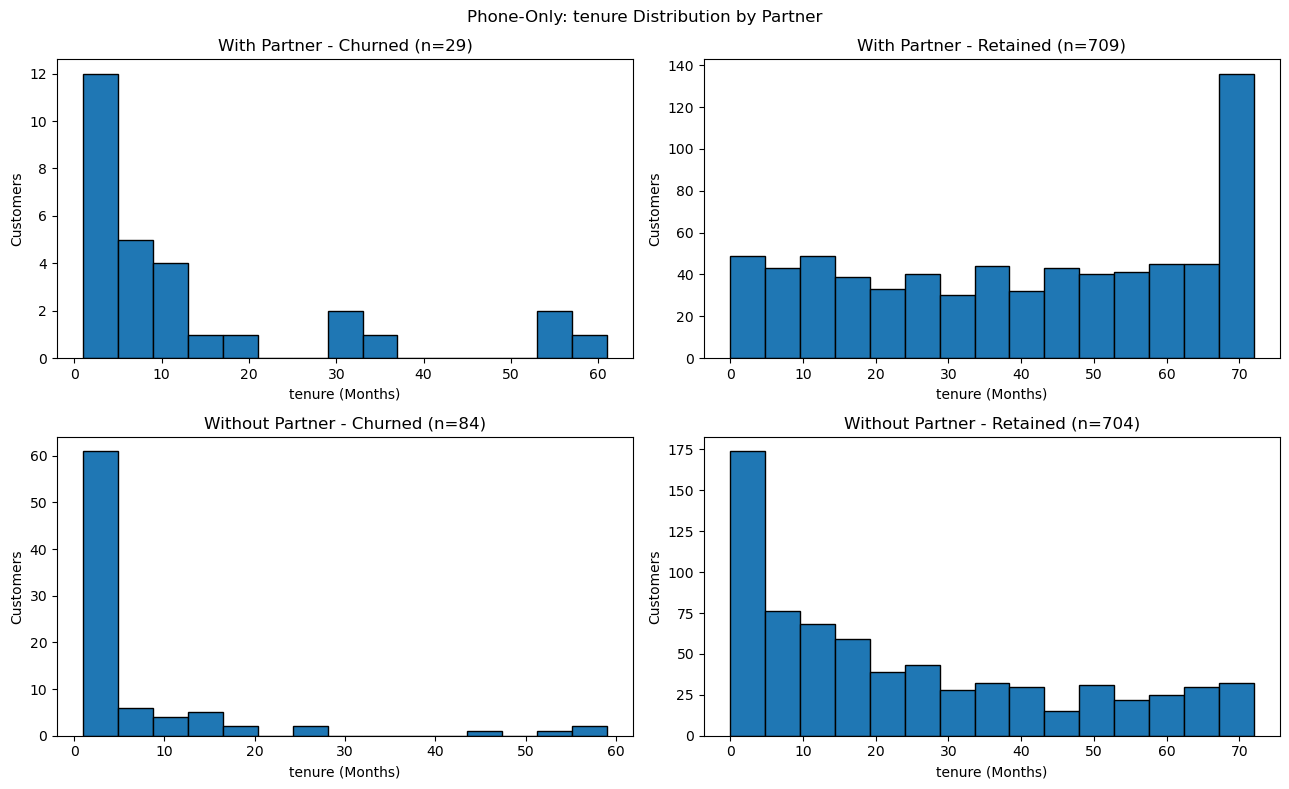

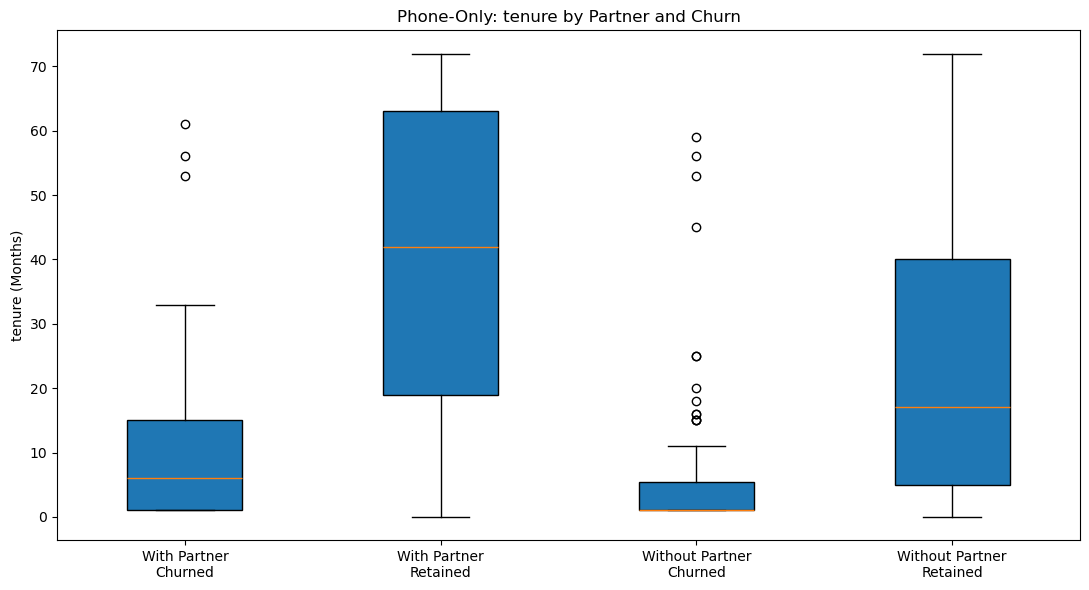

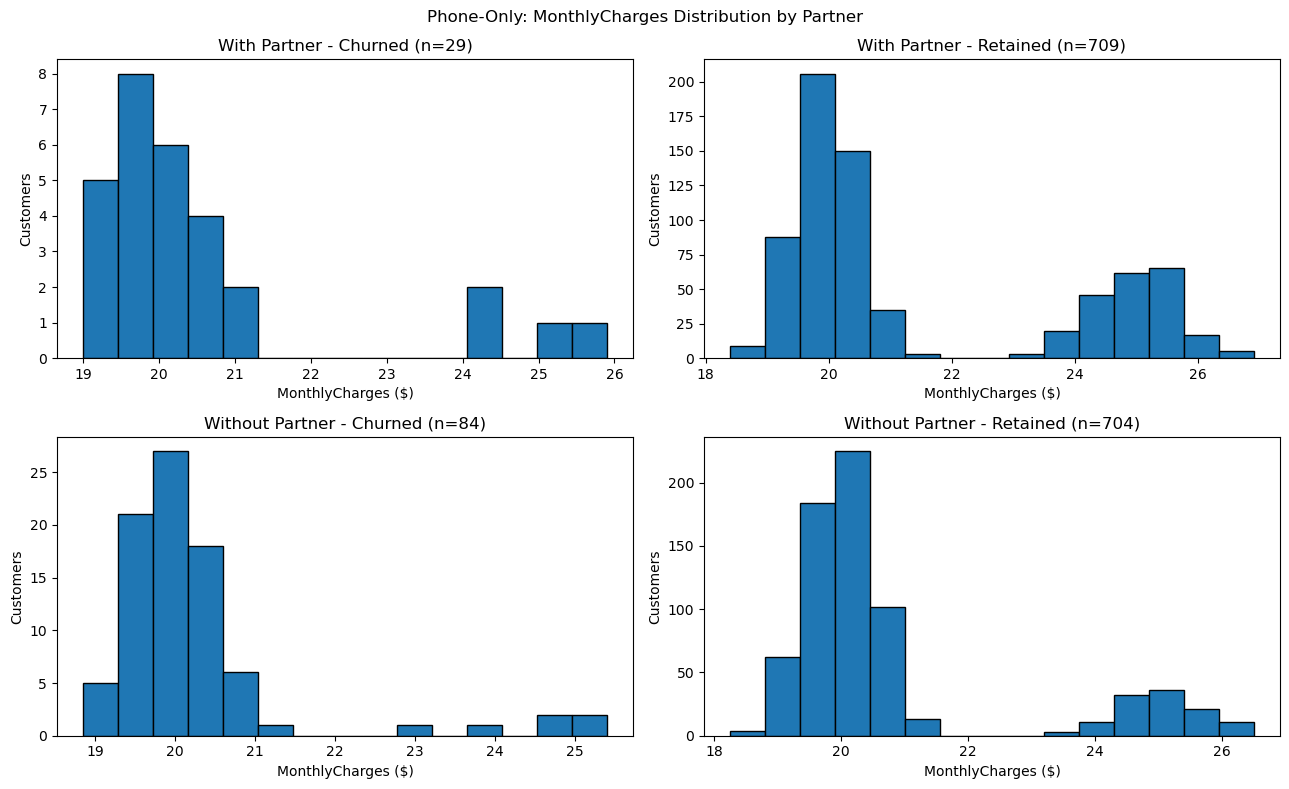

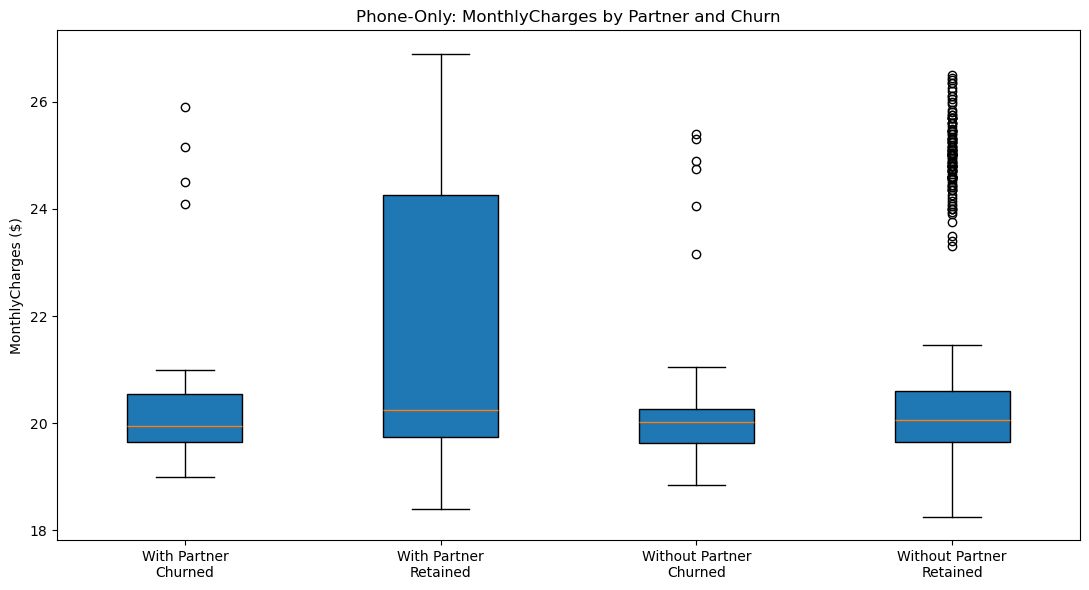


PARTNER — PHONE LINE CHURN SUMMARY


Churn                                  Retained  Churned  Total  \
customer_category phone_line_category                             
With Partner      Multiple Lines            218        4    222   
                  Single Line               491       25    516   
Without Partner   Multiple Lines            114        6    120   
                  Single Line               590       78    668   

Churn                                  Churn Rate (%)  
customer_category phone_line_category                  
With Partner      Multiple Lines                 1.80  
                  Single Line                    4.84  
Without Partner   Multiple Lines                 5.00  
                  Single Line                   11.68

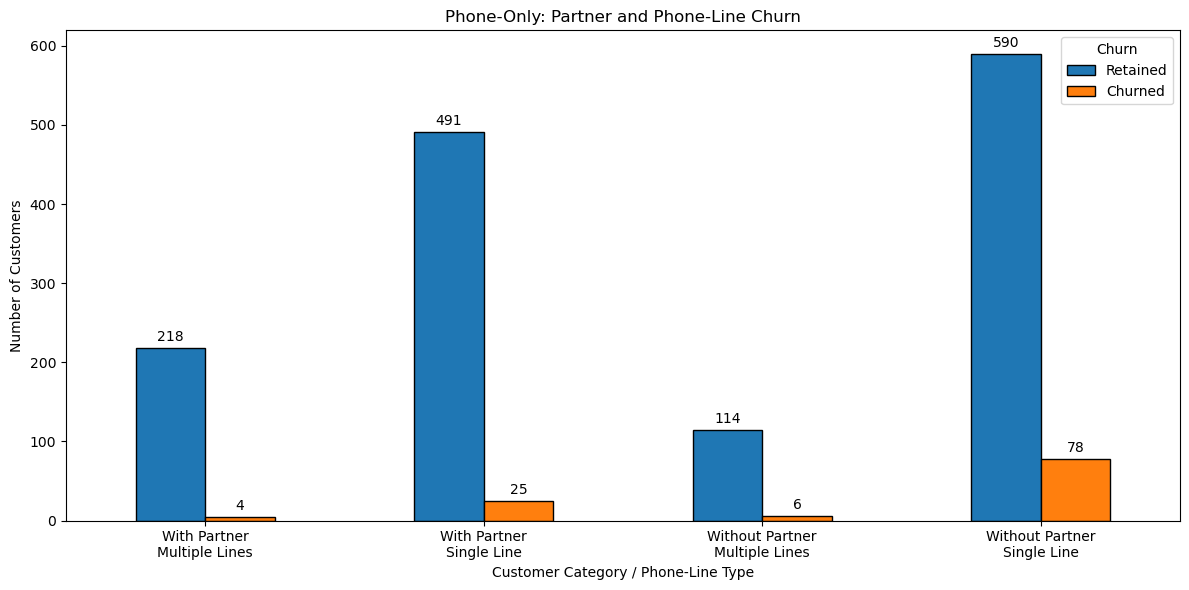

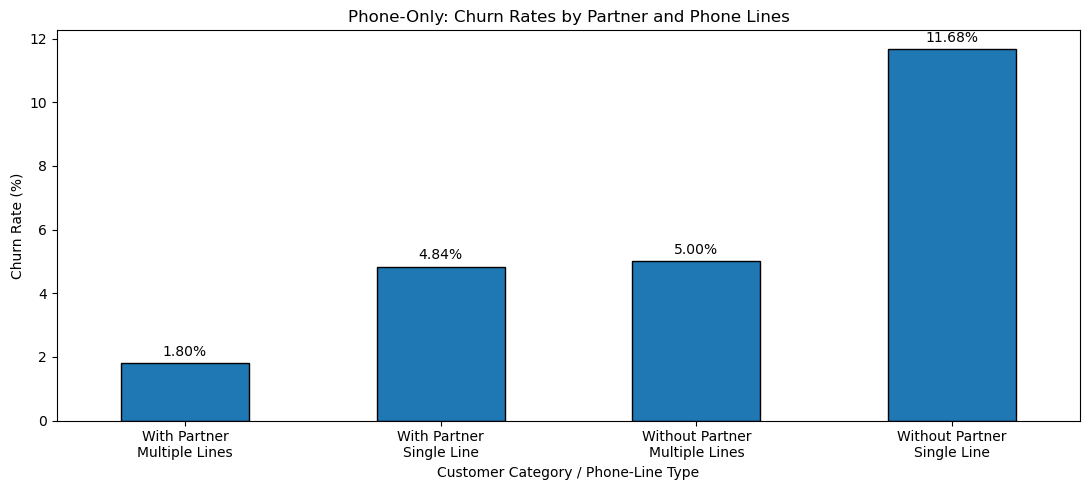

In [51]:
# Customers with and without partner
(
    partner_churn_summary,
    partner_tenure_summary,
    partner_charges_summary,
    partner_lines_summary
) = analyze_phone_segment(
    df_family_phone,
    column="Partner",
    label="Partner"
)


DEPENDENTS — CHURN SUMMARY


Churn,Retained,Churned,Total,Churn Rate (%)
customer_category,,,,
With Dependents,615,28,643,4.35
Without Dependents,798,85,883,9.63


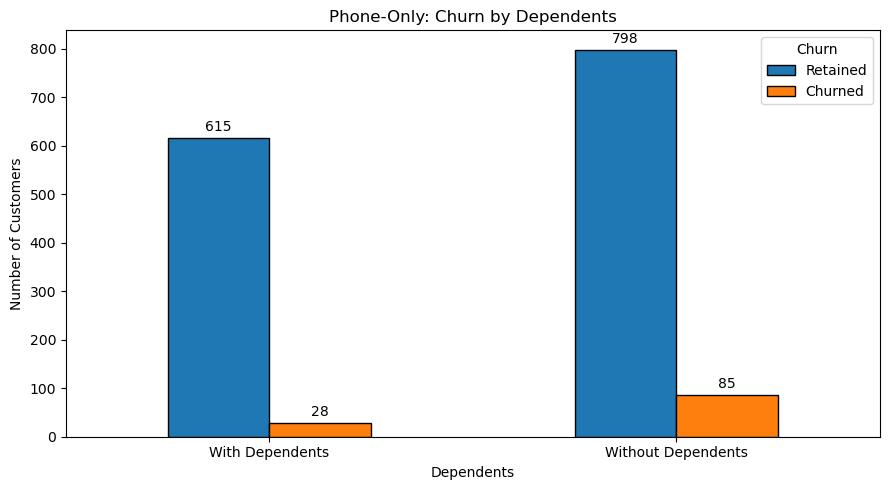

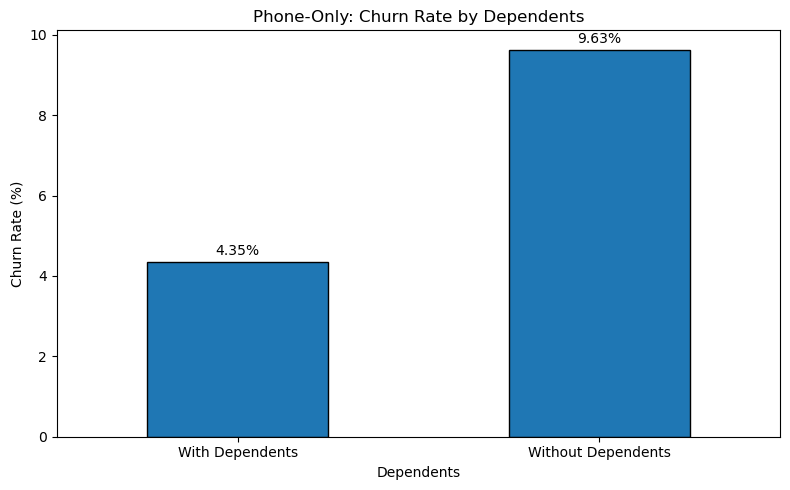


DEPENDENTS — TENURE SUMMARY


Count   Mean  Median  Min  Max  Std_Dev
customer_category  Churn                                         
With Dependents    No       615  35.77    35.0    0   72    23.37
                   Yes       28  11.64     4.5    1   61    15.72
Without Dependents No       798  29.68    23.5    1   72    24.39
                   Yes       85   7.12     1.0    1   59    13.16


DEPENDENTS — MONTHLY CHARGES SUMMARY


Count   Mean  Median    Min    Max  Std_Dev
customer_category  Churn                                             
With Dependents    No       615  21.29   20.20  18.70  26.45     2.27
                   Yes       28  20.37   19.88  19.00  25.90     1.65
Without Dependents No       798  21.02   20.12  18.25  26.90     2.14
                   Yes       85  20.37   20.05  18.85  25.40     1.40

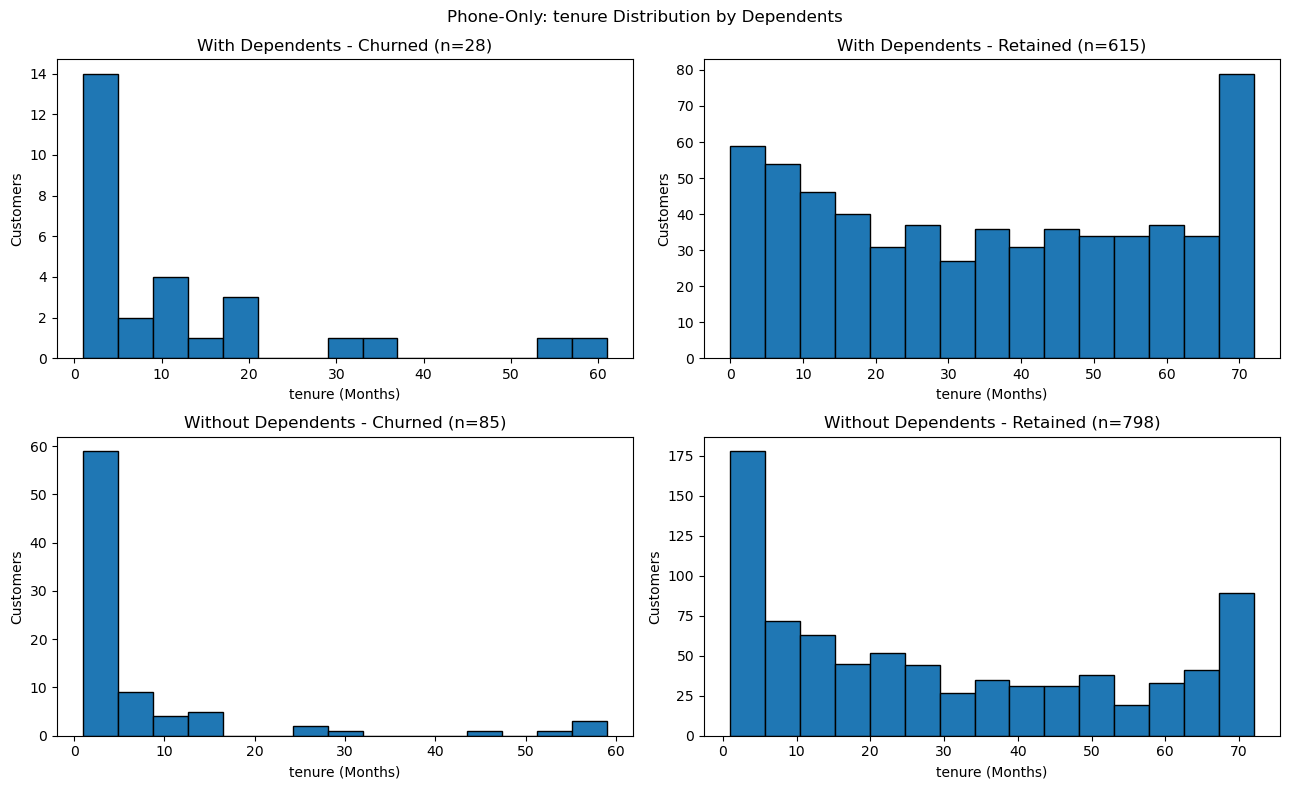

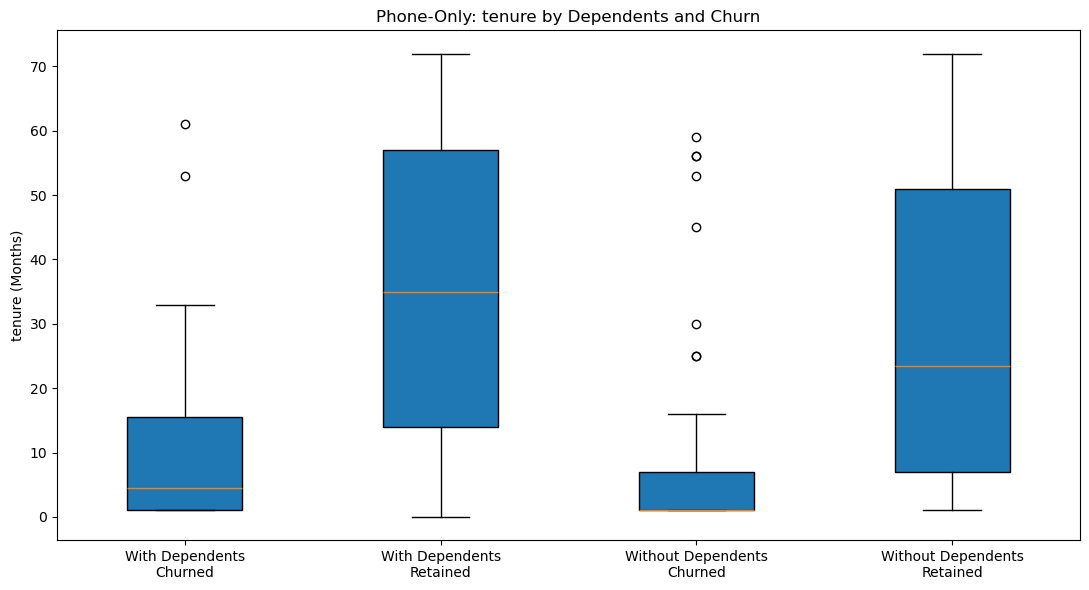

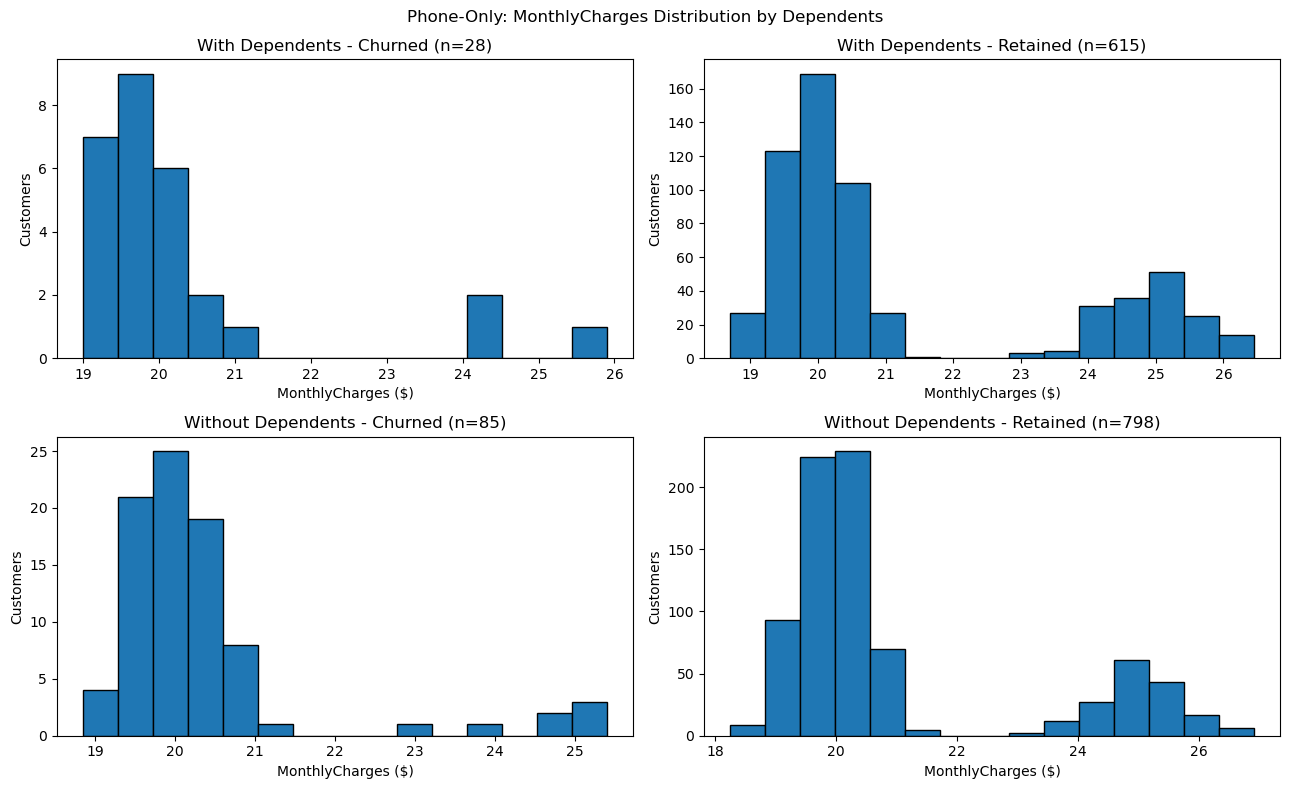

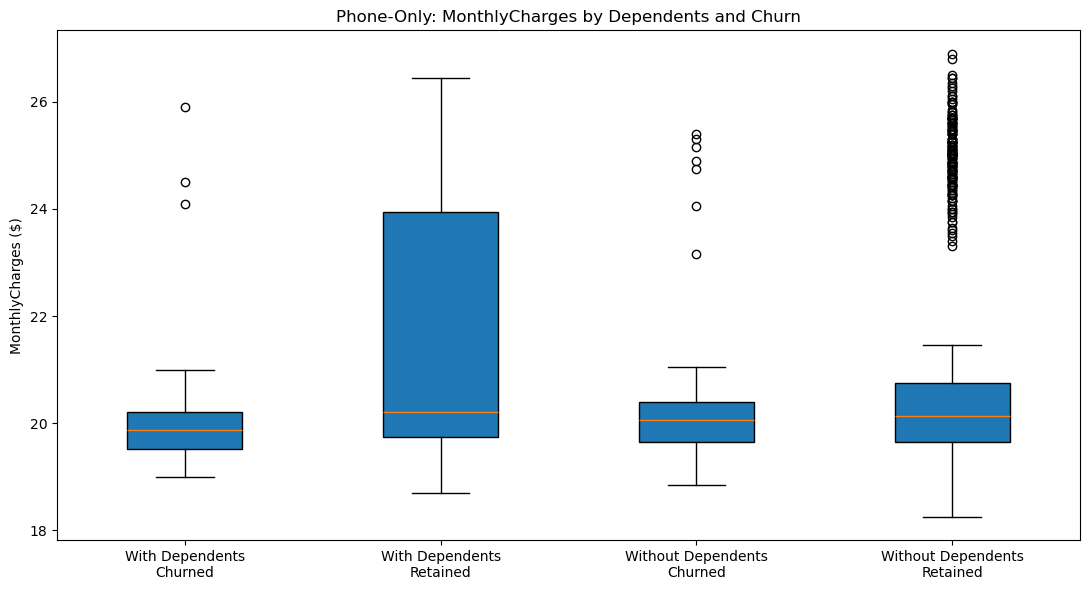


DEPENDENTS — PHONE LINE CHURN SUMMARY


Churn                                   Retained  Churned  Total  \
customer_category  phone_line_category                             
With Dependents    Multiple Lines            164        3    167   
                   Single Line               451       25    476   
Without Dependents Multiple Lines            168        7    175   
                   Single Line               630       78    708   

Churn                                   Churn Rate (%)  
customer_category  phone_line_category                  
With Dependents    Multiple Lines                 1.80  
                   Single Line                    5.25  
Without Dependents Multiple Lines                 4.00  
                   Single Line                   11.02

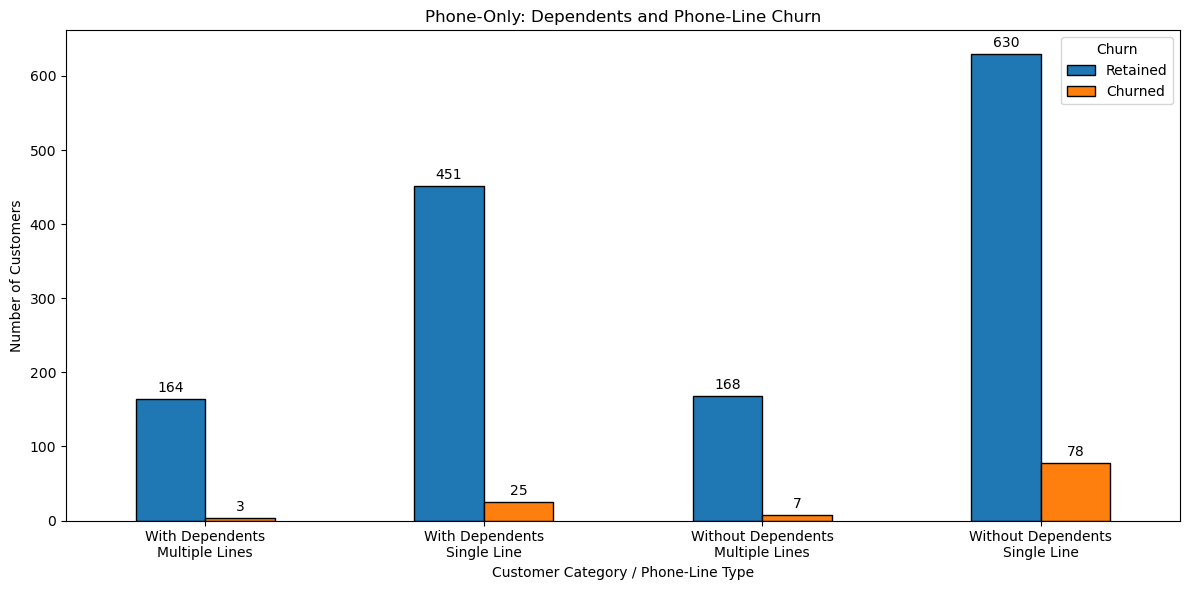

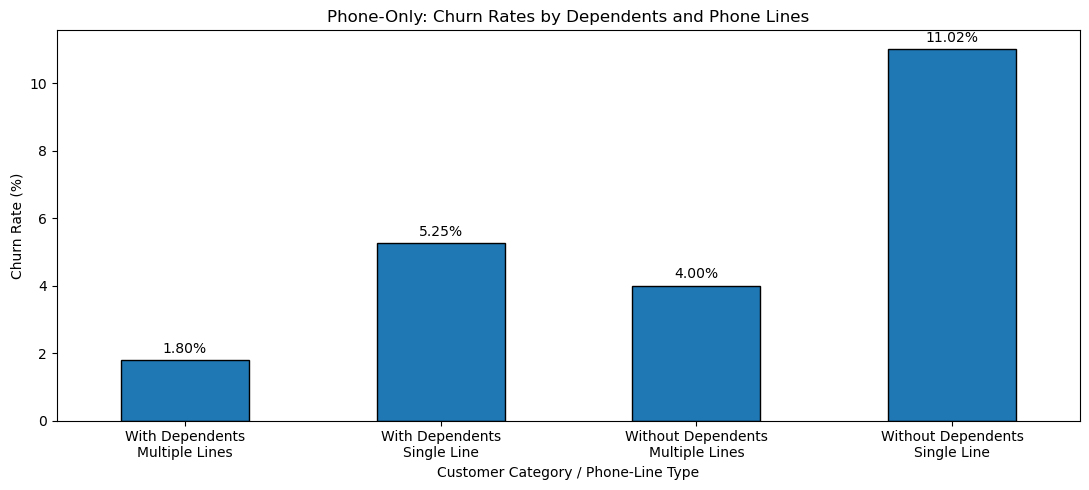

In [52]:
# customers with and without dependents
(
    dependents_churn_summary,
    dependents_tenure_summary,
    dependents_charges_summary,
    dependents_lines_summary
) = analyze_phone_segment(
    df_family_phone,
    column="Dependents",
    label="Dependents"
)